# Test de simulation mimiSBM sur famille GE

Ce notebook teste le modèle mimiSBM entre les descripteurs **Ka** et **Ks** mais aussi la famille **GE** en entier, puis teste sa robustesse a différentes valeurs de bruit selon un mécanisme :

- **Permutation de labels** : reassignation aleatoire de ~(0, 1, 2, 3, 5%) des labels de
  cluster deja obtenus, sans reclustering. Plus rapide, sert de test de robustesse a la
  classification.

Les tests tournent plusieurs fois (graines differentes) pour obtenir une distribution du
taux de recouvrement sous bruit, comparee a la valeur de reference sans bruit.

## Imports

In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import entr

import sys

repo_root = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "mimisbm_main" / "mimisbm" / "_base.py").is_file()
    ),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "Could not find mimisbm_main/mimisbm/_base.py in the notebook's parent directories."
    )

sys.path.insert(0, str(repo_root))
from mimisbm_main.mimisbm._base import MimiSBM


# Configuration
BASE_DIR = Path("../../Données/adjacency/recouvrement")
OUTPUT_DIR = Path("../Plots/mimiSBM/KaKs_permutation_1pct")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MATRIX_PATHS = {
    "Ka": BASE_DIR / "A_Ka_ref.csv",
    "Ks": BASE_DIR / "A_Ks_ref.csv",
}

K_VALUES = range(2, 11)
Q_VALUES = range(1, 5)
N_INIT = 10
PRIORS = "jeffreys"
MAX_ITER = 100
TOL = 1e-6
BASE_SEED = 0
PERMUTATION_SEED = 5
PERMUTATION_RATE = 0.05

### Assemblage tenseur et matrices d'adjacences

In [2]:
def load_adjacency_matrices(paths, header):
    matrices = {}
    for name, path in paths.items():
        matrix = pd.read_csv(path, header=header).to_numpy()

        if not np.all(np.isin(np.unique(matrix), [0, 1])):
            raise ValueError(f"{name}: la matrice contient des valeurs hors de {{0, 1}}.")
        if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
            raise ValueError(f"{name}: la matrice doit etre carree.")

        matrix = matrix.astype(np.int64)
        np.fill_diagonal(matrix, 0)
        matrix = np.maximum(matrix, matrix.T)
        matrices[name] = matrix

    shapes = {matrix.shape for matrix in matrices.values()}
    if len(shapes) != 1:
        raise ValueError(f"Tailles de matrices incompatibles: {shapes}")

    return matrices


def build_tensor(matrices):
    names = list(matrices)
    tensor = np.stack([matrices[name] for name in names], axis=2)
    return tensor, names


def permute_adjacency_labels(adjacency, rate, rng):
    """Reaffecte aleatoirement rate des individus a un autre cluster."""
    adjacency = np.maximum(adjacency, adjacency.T).astype(bool)
    same_cluster = adjacency.copy()
    np.fill_diagonal(same_cluster, True)

    # Les lignes identiques identifient les clusters, y compris les singletons.
    _, labels = np.unique(same_cluster, axis=0, return_inverse=True)
    clusters = np.unique(labels)

    if len(clusters) < 2:
        raise ValueError("Il faut au moins deux clusters pour permuter les labels.")

    n_changed = round(rate * len(labels))
    selected = rng.choice(len(labels), size=n_changed, replace=False)

    for index in selected:
        alternatives = clusters[clusters != labels[index]]
        labels[index] = rng.choice(alternatives)

    permuted = (labels[:, None] == labels[None, :]).astype(np.int64)
    np.fill_diagonal(permuted, 0)
    return permuted

### Fonctions modèles et critères

In [3]:
def fit_best_of_n_init(tensor, k, q):
    best_model = None
    best_elbo = -np.inf
    best_seed = None

    for run in range(N_INIT):
        seed = BASE_SEED + run
        model = MimiSBM(
            n_clusters=k,
            n_components=q,
            clusters_prior=PRIORS,
            components_prior=PRIORS,
            adjacency_prior=PRIORS,
            max_iter=MAX_ITER,
            tol=TOL,
            random_state=seed,
        )
        model.fit(tensor)

        if model.elbo_ > best_elbo:
            best_model = model
            best_elbo = model.elbo_
            best_seed = seed

    return best_model, best_seed


def approximate_icl(model, n, n_views):
    k, q = model.n_clusters, model.n_components
    penalty = (
        0.5 * (k * (k + 1) / 2 * q) * np.log(n_views * n * (n - 1) / 2)
        + 0.5 * (k - 1) * np.log(n)
        + 0.5 * (q - 1) * np.log(n_views)
    )
    return model.elbo_ - penalty


def grid_search(tensor):
    n, _, n_views = tensor.shape
    results = []
    bests = {
        criterion: {"score": -np.inf, "model": None, "K": None, "Q": None}
        for criterion in ("ILVB", "ICL_variationnel", "ICL_approx")
    }

    for k in K_VALUES:
        for q in Q_VALUES:
            model, seed = fit_best_of_n_init(tensor, k, q)

            ilvb = model.elbo_
            icl_variationnel = ilvb - (
                entr(model.cluster_responsibilities_).sum()
                + entr(model.component_responsibilities_).sum()
            )
            icl_approx = approximate_icl(model, n, n_views)

            scores = {
                "ILVB": ilvb,
                "ICL_variationnel": icl_variationnel,
                "ICL_approx": icl_approx,
            }
            results.append({
                "K": k,
                "Q": q,
                **scores,
                "converged": model.converged_,
                "best_seed": seed,
            })

            for criterion, score in scores.items():
                if score > bests[criterion]["score"]:
                    bests[criterion] = {
                        "score": score,
                        "model": model,
                        "K": k,
                        "Q": q,
                    }

    return pd.DataFrame(results), bests

## Lancement baseline

### 2 tenseurs un pour les normal et un pour les permutés

In [4]:
# Matrices originales et matrices avec 5 % des labels reassigned
original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
original_tensor, view_names = build_tensor(original_matrices)

rng = np.random.default_rng(PERMUTATION_SEED)
permuted_matrices = {
    name: permute_adjacency_labels(matrix, PERMUTATION_RATE, rng)
    for name, matrix in original_matrices.items()
}
permuted_tensor, _ = build_tensor(permuted_matrices)

# Ajustement mimiSBM separe sur les donnees originales et permutees
results_by_scenario = {}
bests_by_scenario = {}

for scenario, tensor in {
    "original": original_tensor,
    "permute_5pct": permuted_tensor,
}.items():
    print(f"\nAjustement mimiSBM : {scenario}")
    results_by_scenario[scenario], bests_by_scenario[scenario] = grid_search(tensor)

# Comparaison des meilleurs modeles selon chaque critere
summary = pd.DataFrame([
    {
        "scenario": scenario,
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for scenario, bests in bests_by_scenario.items()
    for criterion, best in bests.items()
])

display(summary)

# Sauvegarde des resultats et des meilleurs modeles
all_results = pd.concat(
    [df.assign(scenario=scenario) for scenario, df in results_by_scenario.items()],
    ignore_index=True,
)
all_results.to_csv(OUTPUT_DIR / "grid_search_results.csv", index=False)
summary.to_csv(OUTPUT_DIR / "best_models_summary.csv", index=False)

with open(OUTPUT_DIR / "best_models.pkl", "wb") as file:
    pickle.dump(bests_by_scenario, file)

print(f"\nResultats sauvegardes dans : {OUTPUT_DIR}")


Ajustement mimiSBM : original

Ajustement mimiSBM : permute_5pct


,scenario,critere,K,Q,score
0,original,ILVB,6,2,-789.718971
1,original,ICL_variationnel,6,2,-789.718971
2,original,ICL_approx,6,2,-1061.282387
3,permute_5pct,ILVB,6,2,-854.587579
4,permute_5pct,ICL_variationnel,6,2,-854.587579
5,permute_5pct,ICL_approx,6,2,-1126.150995



Resultats sauvegardes dans : ../Plots/mimiSBM/KaKs_permutation_1pct


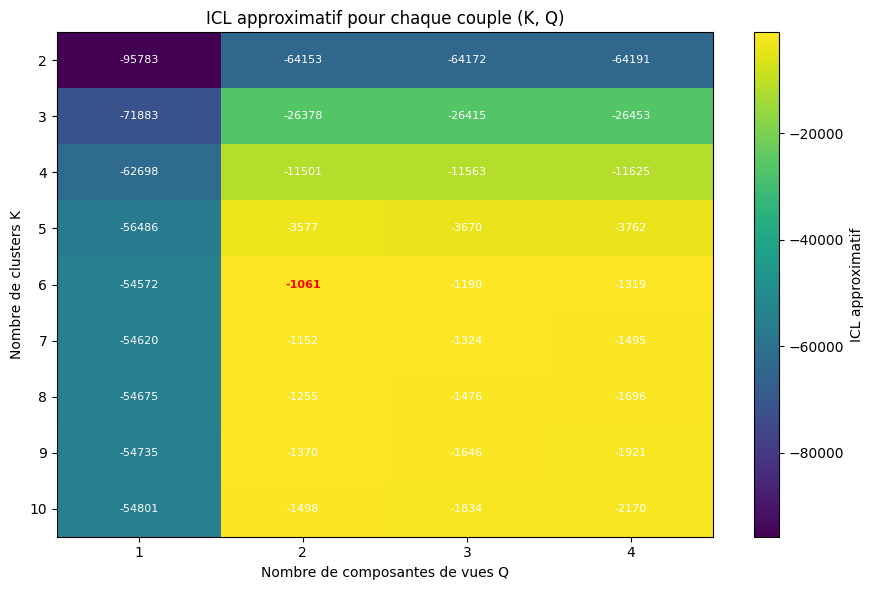

In [5]:
icl_matrix = results_by_scenario["original"].pivot(
    index="K",
    columns="Q",
    values="ICL_approx",
)

plt.figure(figsize=(9, 6))
plt.imshow(icl_matrix.values, aspect="auto", cmap="viridis")

plt.xticks(range(len(icl_matrix.columns)), icl_matrix.columns)
plt.yticks(range(len(icl_matrix.index)), icl_matrix.index)
plt.xlabel("Nombre de composantes de vues Q")
plt.ylabel("Nombre de clusters K")
plt.title("ICL approximatif pour chaque couple (K, Q)")

icl_values = icl_matrix.to_numpy()
max_i, max_j = np.unravel_index(np.nanargmax(icl_values), icl_values.shape)

for i in range(icl_matrix.shape[0]):
    for j in range(icl_matrix.shape[1]):
        is_max = (i == max_i and j == max_j)
        plt.text(
            j,
            i,
            f"{icl_matrix.iloc[i, j]:.0f}",
            ha="center",
            va="center",
            color="red" if is_max else "white",
            fontweight="bold" if is_max else "normal",
            fontsize=8,
        )

plt.colorbar(label="ICL approximatif")
plt.tight_layout()
plt.show()

### 4 descripteurs (2 normaux et 2 permutés) pour un tenseur

In [6]:
# # Charger les matrices originales
# original_matrices = load_adjacency_matrices(MATRIX_PATHS)
# PERMUTATION_RATE = 0.05 # 5% de bruit

# # Creer les versions permutees avec 5 % des labels reassigned
# rng = np.random.default_rng(PERMUTATION_SEED)
# permuted_matrices = {
#     name: permute_adjacency_labels(
#         matrix,
#         PERMUTATION_RATE,
#         rng,
#     )
#     for name, matrix in original_matrices.items()
# }

# # Assembler les deux matrices originales et les deux matrices permutees
# mixed_matrices = {
#     "Ka_original": original_matrices["Ka"],
#     "Ks_original": original_matrices["Ks"],
#     "Ka_permuted": permuted_matrices["Ka"],
#     "Ks_permuted": permuted_matrices["Ks"],
# }

# # build_tensor prend un seul dictionnaire de matrices
# mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)

# print(f"Tenseur mimiSBM : shape={mixed_tensor.shape}")
# print(f"Ordre des vues : {mixed_view_names}")

# # Ajuster mimiSBM sur le tenseur a quatre vues
# mixed_results_df, mixed_bests = grid_search(mixed_tensor)

# # Resume du meilleur modele selon chaque critere
# summary = pd.DataFrame([
#     {
#         "critere": criterion,
#         "K": best["K"],
#         "Q": best["Q"],
#         "score": best["score"],
#     }
#     for criterion, best in mixed_bests.items()
# ])

# display(summary)

### Visualisation itérations modèles

In [7]:
# icl_matrix = mixed_results_df.pivot(
#     index="K",
#     columns="Q",
#     values="ICL_approx",
# )

# plt.figure(figsize=(9, 6))
# plt.imshow(icl_matrix.values, aspect="auto", cmap="viridis")

# plt.xticks(range(len(icl_matrix.columns)), icl_matrix.columns)
# plt.yticks(range(len(icl_matrix.index)), icl_matrix.index)
# plt.xlabel("Number of components in views Q")
# plt.ylabel("Number of clusters K")
# plt.title("ICL approximate for each couple (K, Q)")

# icl_values = icl_matrix.to_numpy()
# max_i, max_j = np.unravel_index(np.nanargmax(icl_values), icl_values.shape)

# for i in range(icl_matrix.shape[0]):
#     for j in range(icl_matrix.shape[1]):
#         is_max = (i == max_i and j == max_j)
#         plt.text(
#             j,
#             i,
#             f"{icl_matrix.iloc[i, j]:.0f}",
#             ha="center",
#             va="center",
#             color="red" if is_max else "white",
#             fontweight="bold" if is_max else "normal",
#             fontsize=8,
#         )

# plt.colorbar(label="ICL approximate")
# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "ICL_approx_mixed_views.png", dpi=150)
# plt.show()

In [8]:
# # Charger les matrices originales
# original_matrices = load_adjacency_matrices(MATRIX_PATHS)

# # Assembler les deux matrices originales et les deux matrices copiées (sans permutation)
# mixed_matrices = {
#     "Ka_original": original_matrices["Ka"],
#     "Ks_original": original_matrices["Ks"],
#     "Ka_permuted": original_matrices["Ka"],
#     "Ks_permuted": original_matrices["Ks"],
# }

# # build_tensor prend un seul dictionnaire de matrices
# mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)

# print(f"Tenseur mimiSBM : shape={mixed_tensor.shape}")
# print(f"Ordre des vues : {mixed_view_names}")

# # Ajuster mimiSBM sur le tenseur a quatre vues
# mixed_results_df, mixed_bests = grid_search(mixed_tensor)

# # Resume du meilleur modele selon chaque critere
# summary = pd.DataFrame([
#     {
#         "critere": criterion,
#         "K": best["K"],
#         "Q": best["Q"],
#         "score": best["score"],
#     }
#     for criterion, best in mixed_bests.items()
# ])

# display(summary)

In [9]:
# icl_matrix = mixed_results_df.pivot(
#     index="K",
#     columns="Q",
#     values="ICL_approx",
# )

# plt.figure(figsize=(9, 6))
# plt.imshow(icl_matrix.values, aspect="auto", cmap="viridis")

# plt.xticks(range(len(icl_matrix.columns)), icl_matrix.columns)
# plt.yticks(range(len(icl_matrix.index)), icl_matrix.index)
# plt.xlabel("Number of components in views Q")
# plt.ylabel("Number of clusters K")
# plt.title("ICL approximate for each couple (K, Q)")

# icl_values = icl_matrix.to_numpy()
# max_i, max_j = np.unravel_index(np.nanargmax(icl_values), icl_values.shape)

# for i in range(icl_matrix.shape[0]):
#     for j in range(icl_matrix.shape[1]):
#         is_max = (i == max_i and j == max_j)
#         plt.text(
#             j,
#             i,
#             f"{icl_matrix.iloc[i, j]:.0f}",
#             ha="center",
#             va="center",
#             color="red" if is_max else "white",
#             fontweight="bold" if is_max else "normal",
#             fontsize=8,
#         )

# plt.colorbar(label="ICL approximate")
# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "ICL_approx_mixed_views.png", dpi=150)
# plt.show()

### 10 runs à 0% de bruit

In [10]:
# N_RUNS = 10
# PERMUTATION_RATE = 0.0 # 0 % de bruit
# rng = np.random.default_rng(PERMUTATION_SEED)

# original_matrices = load_adjacency_matrices(MATRIX_PATHS)
# runs = []

# for run in range(1, N_RUNS + 1):
#     # Générer de nouvelles versions bruitées à chaque run
#     permuted_matrices = {
#         name: permute_adjacency_labels(
#             matrix,
#             PERMUTATION_RATE,
#             rng,
#         )
#         for name, matrix in original_matrices.items()
#     }

#     mixed_matrices = {
#         "Ka_original": original_matrices["Ka"],
#         "Ks_original": original_matrices["Ks"],
#         "Ka_permuted": permuted_matrices["Ka"],
#         "Ks_permuted": permuted_matrices["Ks"],
#     }

#     mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)
#     print(f"Run {run}/{N_RUNS} — tenseur : {mixed_tensor.shape}")

#     _, mixed_bests = grid_search(mixed_tensor)

#     for criterion, best in mixed_bests.items():
#         runs.append({
#             "run": run,
#             "critere": criterion,
#             "K": best["K"],
#             "Q": best["Q"],
#             "score": best["score"],
#         })

# # Résultats détaillés des 10 runs
# runs_df = pd.DataFrame(runs)
# display(runs_df)

# # Boxplots de K et Q, séparés par critère
# criteria = runs_df["critere"].drop_duplicates().tolist()
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# for ax, variable in zip(axes, ["K", "Q"]):
#     values_by_criterion = [
#         runs_df.loc[runs_df["critere"] == criterion, variable].dropna().to_numpy()
#         for criterion in criteria
#     ]

#     ax.boxplot(values_by_criterion, labels=criteria)
#     ax.set_title(f"Values of {variable} on {N_RUNS} runs")
#     ax.set_ylabel(variable)
#     ax.tick_params(axis="x", rotation=30)
#     ax.grid(axis="y", alpha=0.3)

# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "K_Q_boxplots_runs_noise_0.png", dpi=150)
# plt.show()

### Test fonctions et modèle avec un bruit à 0% (aucune modification des descripteurs originaux)

In [11]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
PERMUTATION_RATE = 0.00  # 0% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_0pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_0pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_0pct["Ka"],
    "Ks_permuted": permuted_matrices_0pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_0pct, mixed_view_names_0pct = build_tensor(mixed_matrices_0pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_0pct.shape}")
print(f"Ordre des vues : {mixed_view_names_0pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_0pct, mixed_bests_0pct = grid_search(mixed_tensor_0pct)

# Resume du meilleur modele selon chaque critere
summary_0pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_0pct.items()
])

display(summary_0pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,6,2,-805.921098
1,ICL_variationnel,6,2,-805.921098
2,ICL_approx,6,2,-1092.387178


In [12]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_0pct = mixed_bests_0pct["ICL_approx"]["model"]
node_clusters_0pct, view_components_0pct = best_model_0pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_0pct['ICL_approx']['K']}, {mixed_bests_0pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_0pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_0pct,
        "composante": view_components_0pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (6, 2)

Tailles des clusters d'individus (K):
0    191
1    108
2    102
3     26
4     13
5      4
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           1
1  Ks_original           0
2  Ka_permuted           1
3  Ks_permuted           0


## Duplication avec différentes valeurs de bruits (1, 2, 3, 5 %)

### 10 runs à 1% de bruit

In [13]:
# N_RUNS = 10
# PERMUTATION_RATE = 0.01  # 5 % de bruit
# rng = np.random.default_rng(PERMUTATION_SEED)

# original_matrices = load_adjacency_matrices(MATRIX_PATHS)
# runs = []

# for run in range(1, N_RUNS + 1):
#     # Générer de nouvelles versions bruitées à chaque run
#     permuted_matrices = {
#         name: permute_adjacency_labels(
#             matrix,
#             PERMUTATION_RATE,
#             rng,
#         )
#         for name, matrix in original_matrices.items()
#     }

#     mixed_matrices = {
#         "Ka_original": original_matrices["Ka"],
#         "Ks_original": original_matrices["Ks"],
#         "Ka_permuted": permuted_matrices["Ka"],
#         "Ks_permuted": permuted_matrices["Ks"],
#     }

#     mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)
#     print(f"Run {run}/{N_RUNS} — tenseur : {mixed_tensor.shape}")

#     _, mixed_bests = grid_search(mixed_tensor)

#     for criterion, best in mixed_bests.items():
#         runs.append({
#             "run": run,
#             "critere": criterion,
#             "K": best["K"],
#             "Q": best["Q"],
#             "score": best["score"],
#         })

# # Résultats détaillés des 10 runs
# runs_df = pd.DataFrame(runs)
# display(runs_df)

# # Boxplots de K et Q, séparés par critère
# criteria = runs_df["critere"].drop_duplicates().tolist()
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# for ax, variable in zip(axes, ["K", "Q"]):
#     values_by_criterion = [
#         runs_df.loc[runs_df["critere"] == criterion, variable].dropna().to_numpy()
#         for criterion in criteria
#     ]

#     ax.boxplot(values_by_criterion, labels=criteria)
#     ax.set_title(f"Values of {variable} on {N_RUNS} runs")
#     ax.set_ylabel(variable)
#     ax.tick_params(axis="x", rotation=30)
#     ax.grid(axis="y", alpha=0.3)

# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "K_Q_boxplots_runs_noise_0.01.png", dpi=150)
# plt.show()

### 10 runs pour noise = 5%

In [14]:
# N_RUNS = 10
# PERMUTATION_RATE = 0.05  # 5 % de bruit
# rng = np.random.default_rng(PERMUTATION_SEED)

# original_matrices = load_adjacency_matrices(MATRIX_PATHS)
# runs = []

# for run in range(1, N_RUNS + 1):
#     # Générer de nouvelles versions bruitées à chaque run
#     permuted_matrices = {
#         name: permute_adjacency_labels(
#             matrix,
#             PERMUTATION_RATE,
#             rng,
#         )
#         for name, matrix in original_matrices.items()
#     }

#     mixed_matrices = {
#         "Ka_original": original_matrices["Ka"],
#         "Ks_original": original_matrices["Ks"],
#         "Ka_permuted": permuted_matrices["Ka"],
#         "Ks_permuted": permuted_matrices["Ks"],
#     }

#     mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)
#     print(f"Run {run}/{N_RUNS} — tenseur : {mixed_tensor.shape}")

#     _, mixed_bests = grid_search(mixed_tensor)

#     for criterion, best in mixed_bests.items():
#         runs.append({
#             "run": run,
#             "critere": criterion,
#             "K": best["K"],
#             "Q": best["Q"],
#             "score": best["score"],
#         })

# # Résultats détaillés des 10 runs
# runs_df = pd.DataFrame(runs)
# display(runs_df)

# # Boxplots de K et Q, séparés par critère
# criteria = runs_df["critere"].drop_duplicates().tolist()
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# for ax, variable in zip(axes, ["K", "Q"]):
#     values_by_criterion = [
#         runs_df.loc[runs_df["critere"] == criterion, variable].dropna().to_numpy()
#         for criterion in criteria
#     ]

#     ax.boxplot(values_by_criterion, labels=criteria)
#     ax.set_title(f"Valeurs de {variable} sur {N_RUNS} runs")
#     ax.set_ylabel(variable)
#     ax.tick_params(axis="x", rotation=30)
#     ax.grid(axis="y", alpha=0.3)

# plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "K_Q_boxplots_runs.png", dpi=150)
# plt.show()

### Comparaison avec matrices bruitées à 3%

In [15]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
PERMUTATION_RATE = 0.03  # 3% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_3pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_3pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_3pct["Ka"],
    "Ks_permuted": permuted_matrices_3pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_3pct, mixed_view_names_3pct = build_tensor(mixed_matrices_3pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_3pct.shape}")
print(f"Ordre des vues : {mixed_view_names_3pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_3pct, mixed_bests_3pct = grid_search(mixed_tensor_3pct)

# Resume du meilleur modele selon chaque critere
summary_3pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_3pct.items()
])

display(summary_3pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,8,3,-8035.058365
1,ICL_variationnel,8,3,-8035.058365
2,ICL_approx,8,3,-8753.437287


In [16]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_3pct = mixed_bests_3pct["ICL_approx"]["model"]
node_clusters_3pct, view_components_3pct = best_model_3pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_3pct['ICL_approx']['K']}, {mixed_bests_3pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_3pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_3pct,
        "composante": view_components_3pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (8, 3)

Tailles des clusters d'individus (K):
0    186
1    105
2    101
3     22
4      6
5     13
6      4
7      7
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           1
1  Ks_original           0
2  Ka_permuted           2
3  Ks_permuted           0


### Comparaison avec matrices bruitées à 2 %

In [17]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
PERMUTATION_RATE = 0.02  # 2% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_2pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_2pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_2pct["Ka"],
    "Ks_permuted": permuted_matrices_2pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_2pct, mixed_view_names_2pct = build_tensor(mixed_matrices_2pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_2pct.shape}")
print(f"Ordre des vues : {mixed_view_names_2pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_2pct, mixed_bests_2pct = grid_search(mixed_tensor_2pct)

# Resume du meilleur modele selon chaque critere
summary_2pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_2pct.items()
])

display(summary_2pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,9,4,-4447.394004
1,ICL_variationnel,9,4,-4447.394004
2,ICL_approx,9,4,-5633.285480


In [18]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_2pct = mixed_bests_2pct["ICL_approx"]["model"]
node_clusters_2pct, view_components_2pct = best_model_2pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_2pct['ICL_approx']['K']}, {mixed_bests_2pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_2pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_2pct,
        "composante": view_components_2pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (9, 4)

Tailles des clusters d'individus (K):
0    186
1    107
2    101
3     24
4      6
5     13
7      4
8      3
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           0
1  Ks_original           1
2  Ka_permuted           2
3  Ks_permuted           3


### Comparaison avec matrices bruitées à 1 %

In [19]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
PERMUTATION_RATE = 0.01  # 1% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_1pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_1pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_1pct["Ka"],
    "Ks_permuted": permuted_matrices_1pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_1pct, mixed_view_names_1pct = build_tensor(mixed_matrices_1pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_1pct.shape}")
print(f"Ordre des vues : {mixed_view_names_1pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_1pct, mixed_bests_1pct = grid_search(mixed_tensor_1pct)

# Resume du meilleur modele selon chaque critere
summary_1pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_1pct.items()
])

display(summary_1pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,9,4,-2665.266762
1,ICL_variationnel,9,4,-2665.266762
2,ICL_approx,7,4,-3813.242362


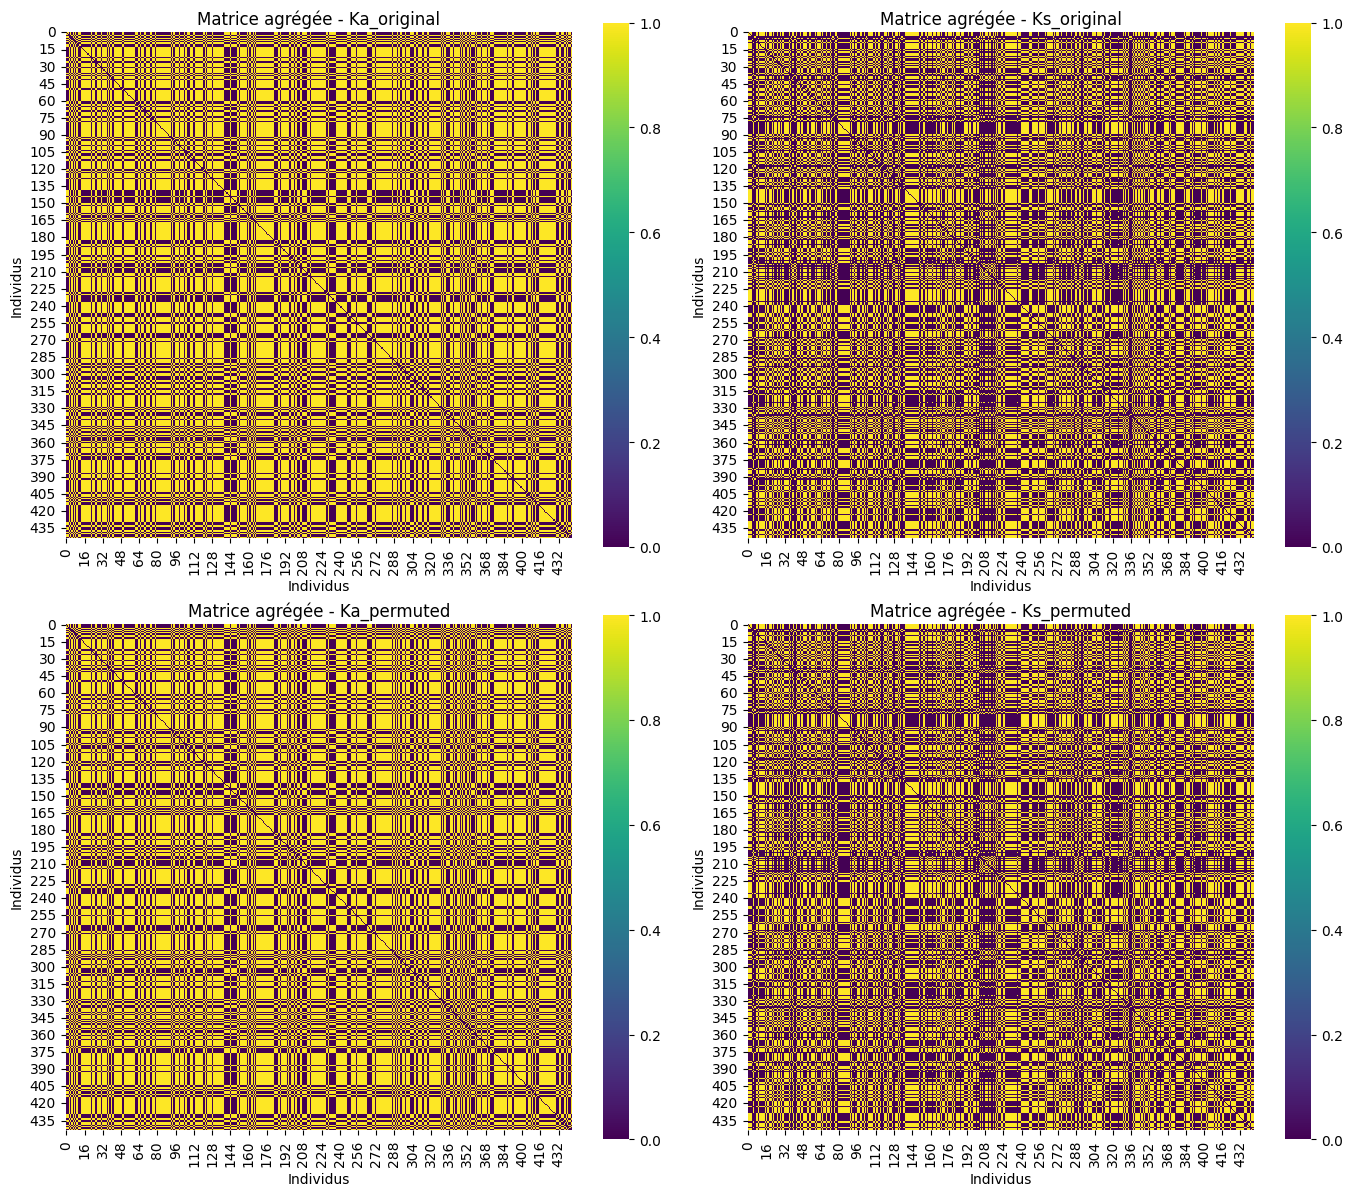

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (family_name, matrix) in zip(axes, mixed_matrices_1pct.items()):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

# Masque les axes inutilisés si moins de 4 matrices
for ax in axes[len(mixed_matrices_1pct):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Matrices ordonnées comparaison original vs bruitées

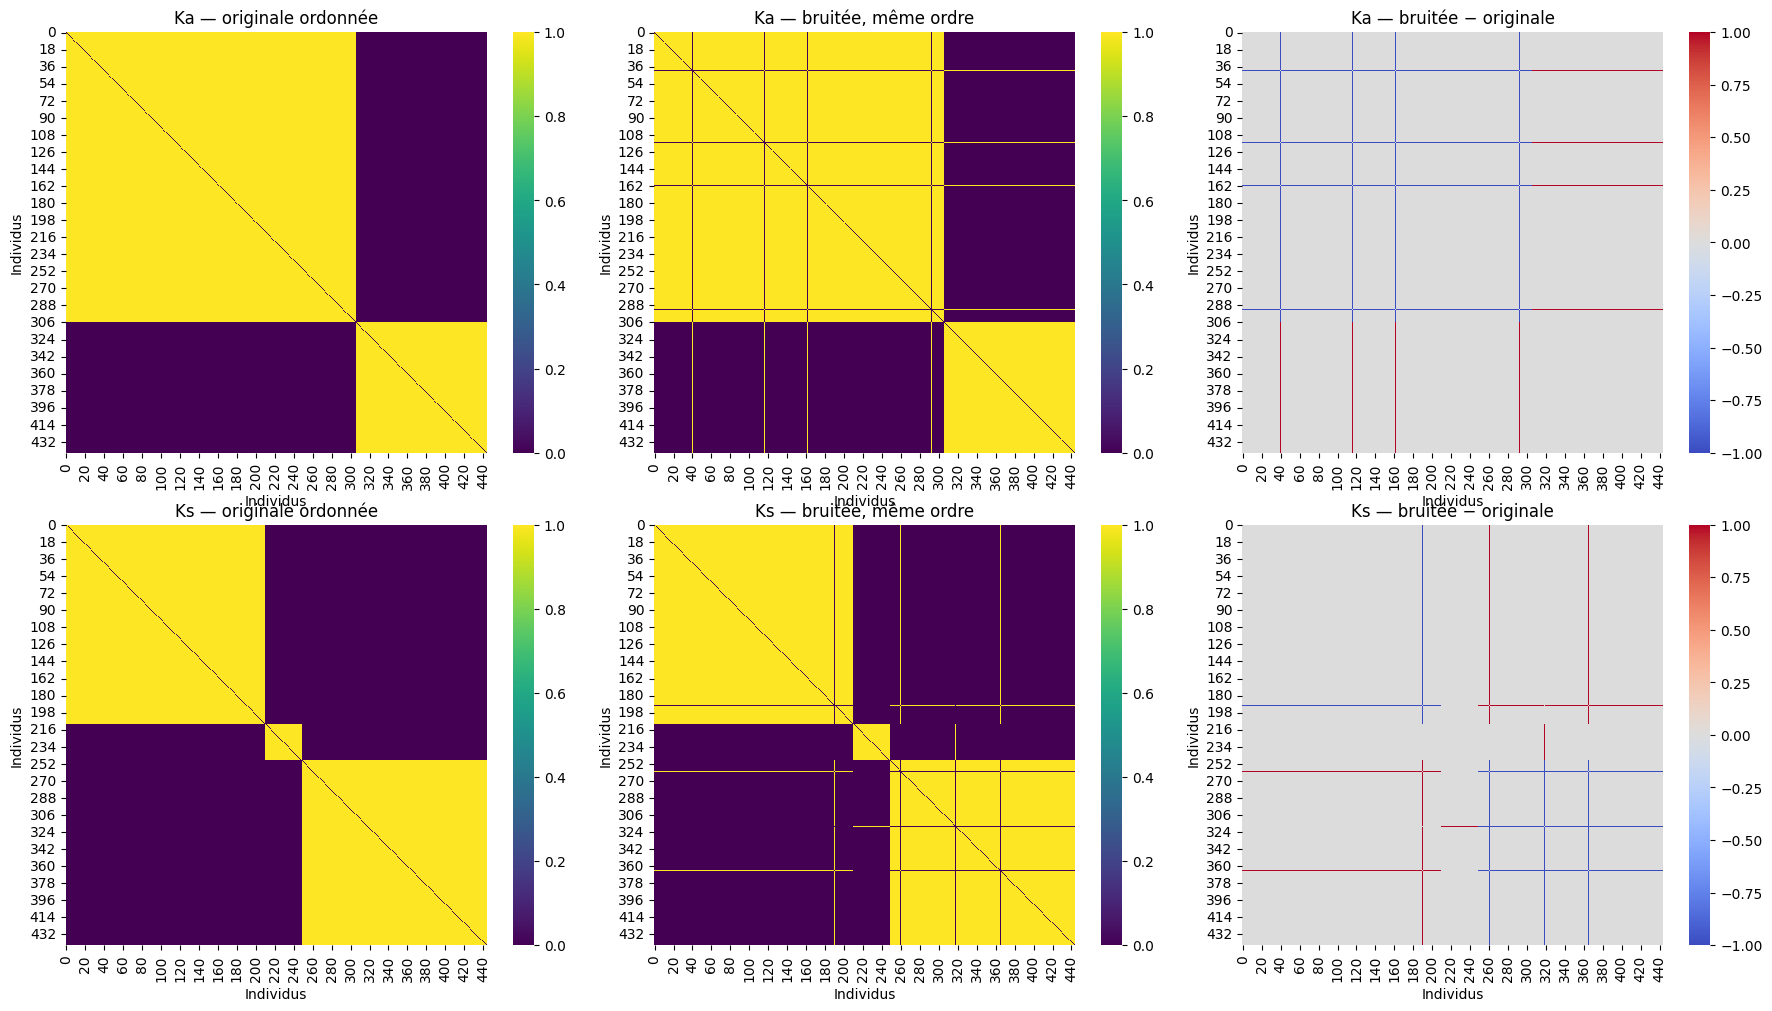

In [21]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist

original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
noisy_matrices = permuted_matrices_1pct  # Matrices avec 1 % de bruit

families = [
    name for name in original_matrices
    if name in noisy_matrices
]

fig, axes = plt.subplots(
    len(families), 3,
    figsize=(18, 5 * len(families)),
    squeeze=False
)

for row, family_name in enumerate(families):
    original = np.asarray(original_matrices[family_name])
    noisy = np.asarray(noisy_matrices[family_name])

    if original.shape != noisy.shape or original.ndim != 2 or original.shape[0] != original.shape[1]:
        raise ValueError(f"Les matrices de {family_name} doivent avoir la même forme carrée.")

    # Calcule un ordre commun à partir des profils de la matrice originale.
    order = leaves_list(linkage(pdist(original), method="average"))

    original_ordered = original[np.ix_(order, order)]
    noisy_ordered = noisy[np.ix_(order, order)]
    difference = noisy_ordered - original_ordered

    # Même échelle de couleurs pour comparer les deux matrices.
    vmin = min(original_ordered.min(), noisy_ordered.min())
    vmax = max(original_ordered.max(), noisy_ordered.max())
    diff_limit = np.max(np.abs(difference)) or 1

    sns.heatmap(
        original_ordered, ax=axes[row, 0],
        cmap="viridis", vmin=vmin, vmax=vmax, square=True
    )
    axes[row, 0].set_title(f"{family_name} — originale ordonnée")

    sns.heatmap(
        noisy_ordered, ax=axes[row, 1],
        cmap="viridis", vmin=vmin, vmax=vmax, square=True
    )
    axes[row, 1].set_title(f"{family_name} — bruitée, même ordre")

    sns.heatmap(
        difference, ax=axes[row, 2],
        cmap="coolwarm", vmin=-diff_limit, vmax=diff_limit,
        center=0, square=True
    )
    axes[row, 2].set_title(f"{family_name} — bruitée − originale")

    for ax in axes[row]:
        ax.set_xlabel("Individus")
        ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [22]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_1pct = mixed_bests_1pct["ICL_approx"]["model"]
node_clusters_1pct, view_components_1pct = best_model_1pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_1pct['ICL_approx']['K']}, {mixed_bests_1pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_1pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_1pct,
        "composante": view_components_1pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (7, 4)

Tailles des clusters d'individus (K):
0    108
1    188
2    101
3     26
4      4
5      4
6     13
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           0
1  Ks_original           1
2  Ka_permuted           2
3  Ks_permuted           3


In [23]:
NOISE_LEVELS_PCT = [0, 1, 2, 3, 5]

noise_results = []

for noise_pct in NOISE_LEVELS_PCT:
    noise_rate = noise_pct / 100

    original_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)

    # Reset the seed at each noise level for reproducibility
    rng = np.random.default_rng(PERMUTATION_SEED)
    permuted_matrices = {
        name: permute_adjacency_labels(matrix, noise_rate, rng)
        for name, matrix in original_matrices.items()
    }

    mixed_matrices = {
        "Ka_original": original_matrices["Ka"],
        "Ks_original": original_matrices["Ks"],
        "Ka_permuted": permuted_matrices["Ka"],
        "Ks_permuted": permuted_matrices["Ks"],
    }

    mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)
    _, mixed_bests = grid_search(mixed_tensor)

    for criterion, best in mixed_bests.items():
        noise_results.append({
            "noise_pct": noise_pct,
            "criterion": criterion,
            "K": best["K"],
            "Q": best["Q"],
            "score": best["score"],
        })

noise_summary = pd.DataFrame(noise_results)
display(
    noise_summary
    .sort_values(["noise_pct", "criterion"])
    .reset_index(drop=True)
)

,noise_pct,criterion,K,Q,score
0,0,ICL_approx,6,2,-1092.387178
1,0,ICL_variationnel,6,2,-805.921098
2,0,ILVB,6,2,-805.921098
3,1,ICL_approx,10,3,-6722.028943
4,1,ICL_variationnel,10,3,-5630.401763
5,1,ILVB,10,3,-5630.401763
6,2,ICL_approx,10,4,-8932.855268
7,2,ICL_variationnel,10,4,-7486.265049
8,2,ILVB,10,4,-7486.265049
9,3,ICL_approx,10,4,-14598.578098


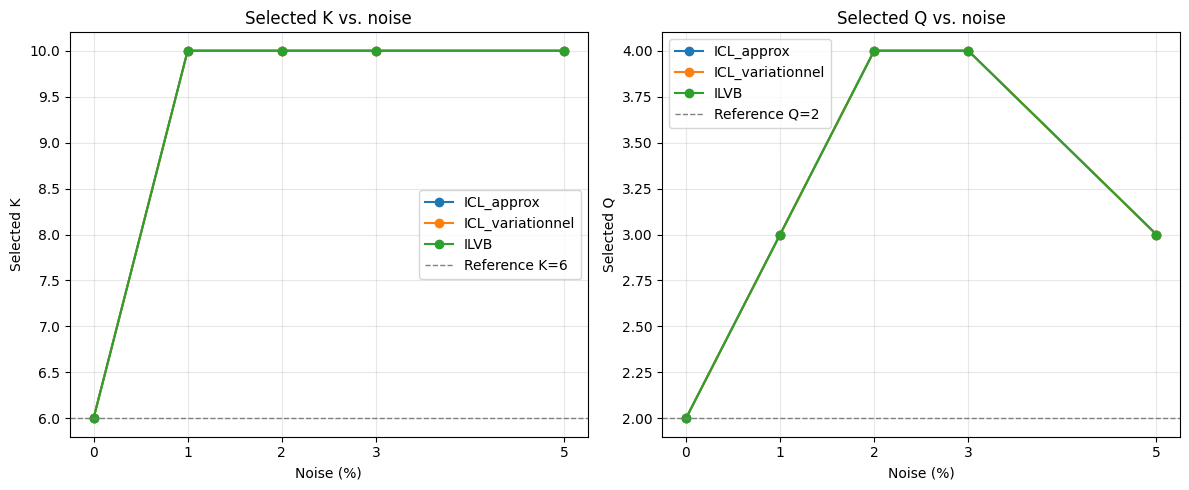

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for criterion, group in noise_summary.groupby("criterion"):
    group = group.sort_values("noise_pct")
    axes[0].plot(group["noise_pct"], group["K"], marker="o", label=criterion)
    axes[1].plot(group["noise_pct"], group["Q"], marker="o", label=criterion)

axes[0].axhline(6, color="gray", linestyle="--", linewidth=1, label="Reference K=6")
axes[1].axhline(2, color="gray", linestyle="--", linewidth=1, label="Reference Q=2")

axes[0].set(title="Selected K vs. noise", xlabel="Noise (%)", ylabel="Selected K")
axes[1].set(title="Selected Q vs. noise", xlabel="Noise (%)", ylabel="Selected Q")

for ax in axes:
    ax.set_xticks(NOISE_LEVELS_PCT)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "selected_K_Q_vs_noise.png", dpi=150)
plt.show()

## Tests comme dans papier

On va tester différentes manières de sélectionner les paramètres K et Q comme expliqué dans le papier:
- **Model Selection sur K** à Q fixé, on va faire varier K en fixant Q au nombre de composantes attendus
- **Model Selection sur Q** à K fixé, on va faire varier Q en fixant K au nombre de clusters attendus

### Model Selection sur K, Q fixé

Famille globale : tenseur (444, 444, 4), Q fixé à 3
Ka et Ks : tenseur (444, 444, 2), Q fixé à 2


,jeu_de_donnees,K,Q,ILVB,ICL_variationnel,ICL_approx,converged,best_seed
0,Famille globale,2,3,-187701.459356,-187701.459356,-187763.864999,True,5
1,Famille globale,3,3,-164914.303155,-164914.303155,-165037.728147,True,3
2,Famille globale,4,3,-129863.323808,-129863.323808,-130067.091962,True,8
3,Famille globale,5,3,-113955.754284,-113955.754284,-114259.189411,True,6
4,Famille globale,6,3,-100861.379489,-100861.379489,-101283.805402,True,8
5,Famille globale,7,3,-74144.381371,-74144.381371,-74705.121883,True,4
6,Famille globale,8,3,-71469.856865,-71469.856865,-72188.235787,True,0
7,Famille globale,9,3,-55810.210957,-55810.210957,-56705.552101,True,7
8,Famille globale,10,3,-49570.776800,-49570.776800,-50662.403980,True,7
9,Famille globale,11,3,-44451.272011,-44451.272011,-45758.509038,True,0


,jeu_de_donnees,critere,K_retenu,score
0,Famille globale,ILVB,12,-39382.829025
1,Famille globale,ICL_variationnel,12,-39382.829025
2,Famille globale,ICL_approx,12,-40924.999712
3,Ka et Ks,ILVB,6,-789.718971
4,Ka et Ks,ICL_variationnel,6,-789.718971
5,Ka et Ks,ICL_approx,6,-1061.282387


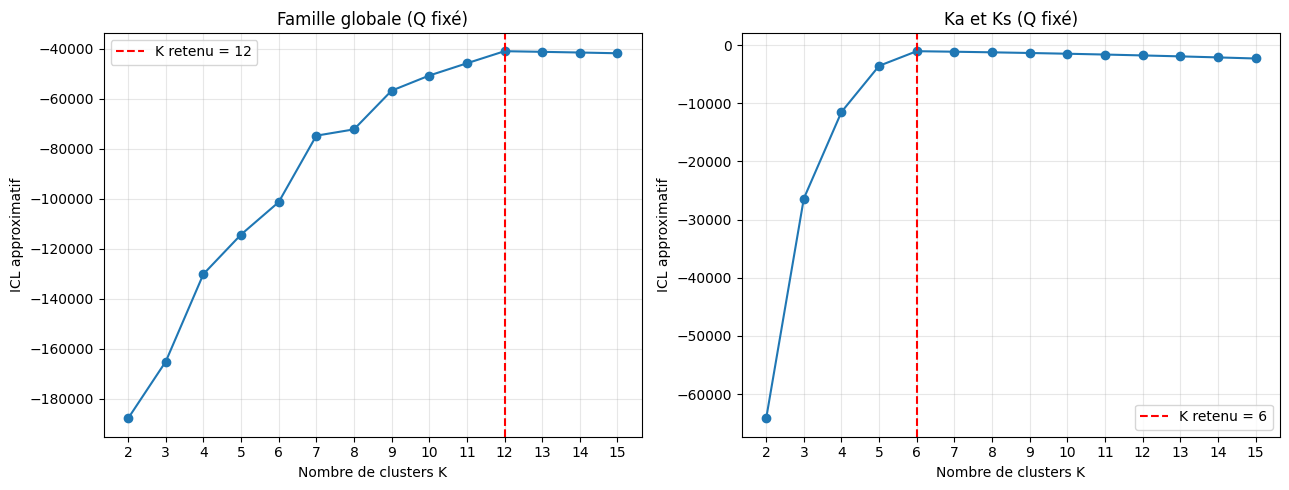

In [25]:
K_VALUES_TEST = range(2, 16)

# Tenseur de la famille globale : quatre vues
FAMILY_BASE_DIR = repo_root.parent / "Données" / "adjacency" / "Ks_et_Ka"

matrix_ka_path = FAMILY_BASE_DIR / "adjacency_matrix_Ka.csv"
matrix_ks_path = FAMILY_BASE_DIR / "adjacency_matrix_Ks.csv"
matrix_distance_path = FAMILY_BASE_DIR / "adjacency_matrix_Distance.csv"
matrix_kaks_path = FAMILY_BASE_DIR / "adjacency_matrix_Ka_Ks.csv"

family_global_matrices = load_adjacency_matrices({
    "Ka": matrix_ka_path,
    "Ks": matrix_ks_path,
    "Distance": matrix_distance_path,
    "Ka_Ks": matrix_kaks_path,
}, header=None)
tensor_famille_globale, noms_vues_globales = build_tensor(family_global_matrices)

# Tenseur Ka/Ks : les deux vues du notebook de simulation
kaks_matrices = load_adjacency_matrices(MATRIX_PATHS, header=0)
tensor_kaks, noms_vues_kaks = build_tensor(kaks_matrices)

# Pour chaque jeu de données, on fait varier K et on fixe Q.
jeux_de_donnees_k = {
    "Famille globale": (tensor_famille_globale, 3),
    "Ka et Ks": (tensor_kaks, 2),
}

resultats_selection_k = {}

for nom, (tensor, q_fixe) in jeux_de_donnees_k.items():
    n, _, n_vues = tensor.shape
    lignes = []

    print(f"{nom} : tenseur {tensor.shape}, Q fixé à {q_fixe}")

    for k in K_VALUES_TEST:
        model, seed = fit_best_of_n_init(tensor, k, q_fixe)

        ilvb = model.elbo_
        icl_variationnel = ilvb - (
            entr(model.cluster_responsibilities_).sum()
            + entr(model.component_responsibilities_).sum()
        )
        icl_approx = approximate_icl(model, n, n_vues)

        lignes.append({
            "jeu_de_donnees": nom,
            "K": k,
            "Q": q_fixe,
            "ILVB": ilvb,
            "ICL_variationnel": icl_variationnel,
            "ICL_approx": icl_approx,
            "converged": model.converged_,
            "best_seed": seed,
        })

    resultats_selection_k[nom] = pd.DataFrame(lignes)

# Tableau récapitulatif : K retenu selon chaque critère
resultats_k = pd.concat(resultats_selection_k.values(), ignore_index=True)

resume_k = pd.DataFrame([
    {
        "jeu_de_donnees": nom,
        "critere": critere,
        "K_retenu": df.loc[df[critere].idxmax(), "K"],
        "score": df[critere].max(),
    }
    for nom, df in resultats_selection_k.items()
    for critere in ("ILVB", "ICL_variationnel", "ICL_approx")
])

display(resultats_k)
display(resume_k)

# Comparaison des scores en fonction de K
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

for ax, (nom, df) in zip(axes, resultats_selection_k.items()):
    ax.plot(df["K"], df["ICL_approx"], marker="o")
    k_optimal = df.loc[df["ICL_approx"].idxmax(), "K"]
    ax.axvline(k_optimal, color="red", linestyle="--",
               label=f"K retenu = {k_optimal}")
    ax.set(
        title=f"{nom} (Q fixé)",
        xlabel="Nombre de clusters K",
        ylabel="ICL approximatif",
        xticks=list(K_VALUES_TEST),
    )
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Model Selection sur Q, K fixé

Famille globale : tenseur (444, 444, 4), K fixé à 10
Ka et Ks : tenseur (444, 444, 2), K fixé à 6


,jeu_de_donnees,K,Q,ILVB,ICL_variationnel,ICL_approx,converged,best_seed
0,Famille globale,10,1,-266555.149003,-266555.149003,-266625.800035,True,0
1,Famille globale,10,2,-184718.145234,-184718.145234,-184920.669593,True,1
2,Famille globale,10,3,-143924.573285,-143924.573285,-144323.383680,True,2
3,Famille globale,10,4,-109443.159070,-109443.159070,-110102.668207,True,8
4,Famille globale,10,5,-90853.288315,-90853.288315,-91837.908902,True,1
5,Famille globale,10,6,-76406.339670,-76406.339670,-77780.484415,True,3
6,Famille globale,10,7,-54889.288601,-54889.288601,-56717.370211,True,8
7,Famille globale,10,8,-38795.831408,-38795.831408,-41142.262591,True,3
8,Famille globale,10,9,-24346.296526,-24346.296526,-27275.489989,True,7
9,Famille globale,10,10,-13355.202153,-13355.202153,-16931.570605,True,8


,jeu_de_donnees,critere,Q_retenu,score
0,Famille globale,ILVB,10,-13355.202153
1,Famille globale,ICL_variationnel,10,-13355.202153
2,Famille globale,ICL_approx,10,-16931.570605
3,Ka et Ks,ILVB,6,-791.510731
4,Ka et Ks,ICL_variationnel,6,-791.510731
5,Ka et Ks,ICL_approx,6,-1576.415003


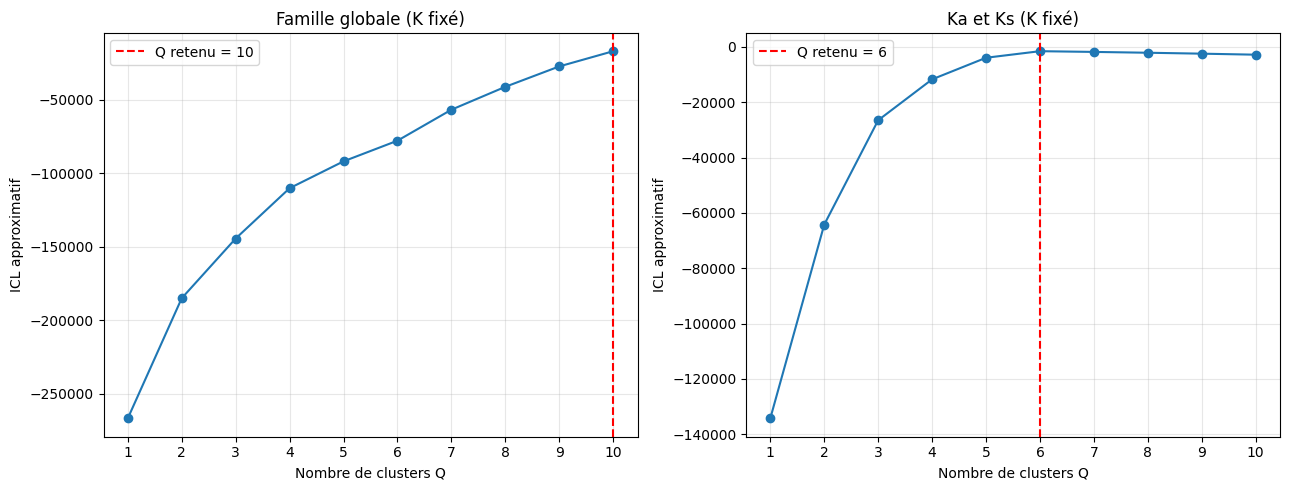

In [26]:
Q_VALUES_TEST = range(1, 11)

# Pour chaque jeu de données, on fait varier Q et on fixe K.
jeux_de_donnees_q = {
    "Famille globale": (tensor_famille_globale, 10),
    "Ka et Ks": (tensor_kaks, 6),
}

resultats_selection_q = {}

for nom, (tensor, k_fixe) in jeux_de_donnees_q.items():
    n, _, n_vues = tensor.shape
    lignes = []

    print(f"{nom} : tenseur {tensor.shape}, K fixé à {k_fixe}")

    for q in Q_VALUES_TEST:
        model, seed = fit_best_of_n_init(tensor, q, k_fixe)

        ilvb = model.elbo_
        icl_variationnel = ilvb - (
            entr(model.cluster_responsibilities_).sum()
            + entr(model.component_responsibilities_).sum()
        )
        icl_approx = approximate_icl(model, n, n_vues)

        lignes.append({
            "jeu_de_donnees": nom,
            "K": k_fixe,
            "Q": q,
            "ILVB": ilvb,
            "ICL_variationnel": icl_variationnel,
            "ICL_approx": icl_approx,
            "converged": model.converged_,
            "best_seed": seed,
        })

    resultats_selection_q[nom] = pd.DataFrame(lignes)

# Tableau récapitulatif : Q retenu selon chaque critère
resultats_q = pd.concat(resultats_selection_q.values(), ignore_index=True)

resume_q = pd.DataFrame([
    {
        "jeu_de_donnees": nom,
        "critere": critere,
        "Q_retenu": df.loc[df[critere].idxmax(), "Q"],
        "score": df[critere].max(),
    }
    for nom, df in resultats_selection_q.items()
    for critere in ("ILVB", "ICL_variationnel", "ICL_approx")
])

display(resultats_q)
display(resume_q)

# Comparaison des scores en fonction de Q
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

for ax, (nom, df) in zip(axes, resultats_selection_q.items()):
    ax.plot(df["Q"], df["ICL_approx"], marker="o")
    q_optimal = df.loc[df["ICL_approx"].idxmax(), "Q"]
    ax.axvline(q_optimal, color="red", linestyle="--",
               label=f"Q retenu = {q_optimal}")
    ax.set(
        title=f"{nom} (K fixé)",
        xlabel="Nombre de clusters Q",
        ylabel="ICL approximatif",
        xticks=list(Q_VALUES_TEST),
    )
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### 50 Simulations sur famille GE et descripteurs Ka et Ks

In [27]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import entr


# Trouve la racine du projet et importe mimiSBM.
repo_root = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "mimisbm_main" / "mimisbm" / "_base.py").is_file()
    ),
    None,
)
if repo_root is None:
    raise FileNotFoundError(
        "Racine du projet introuvable : impossible de trouver "
        "mimisbm_main/mimisbm/_base.py."
    )

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from mimisbm_main.mimisbm._base import MimiSBM


# Les matrices famille globales Ka, Ks, Distance et Ka_Ks.
family_dir = repo_root.parent / "Données" / "adjacency" / "lda" / "family"

paths_familles = {
    "Ka": family_dir / "adjacency_matrix_silh_Ka.csv",
    "Ks": family_dir / "adjacency_matrix_silh_Ks.csv",
    "Distance": family_dir / "adjacency_matrix_silh_Distance.csv",
    "Ka_Ks": family_dir / "adjacency_matrix_silh_Ka_Ks.csv",
}

# Le jeu de données des deux descripteurs Ka et Ks.
paths_kaks = {
    "Ka": family_dir / "adjacency_matrix_silh_Ka.csv",
    "Ks": family_dir / "adjacency_matrix_silh_Ks.csv",
}


def charger_tenseur(paths):
    """Charge des matrices avec index de lignes, puis les assemble en tenseur N×N×V."""
    matrices = {}

    for nom, chemin in paths.items():
        matrice = pd.read_csv(chemin, index_col=0).to_numpy()

        if matrice.ndim != 2 or matrice.shape[0] != matrice.shape[1]:
            raise ValueError(f"{nom}: matrice non carrée après lecture : {matrice.shape}")
        if not np.all(np.isin(np.unique(matrice), [0, 1])):
            raise ValueError(f"{nom}: la matrice contient des valeurs autres que 0 et 1.")

        matrice = matrice.astype(np.int64)
        np.fill_diagonal(matrice, 0)
        matrice = np.maximum(matrice, matrice.T)
        matrices[nom] = matrice

    formes = {matrice.shape for matrice in matrices.values()}
    if len(formes) != 1:
        raise ValueError(f"Tailles de matrices incompatibles : {formes}")

    noms_vues = list(matrices)
    tenseur = np.stack([matrices[nom] for nom in noms_vues], axis=2)
    return tenseur, noms_vues

In [ ]:
A_familles, vues_familles = charger_tenseur(paths_familles)
A_kaks, vues_kaks = charger_tenseur(paths_kaks)

# K vrai et Q vrai pour chaque jeu de données.
jeux = {
    "Familles": (A_familles, 10, 3),
    "Ka et Ks": (A_kaks, 6, 2),
}

print("Familles :", A_familles.shape, vues_familles)
print("Ka et Ks :", A_kaks.shape, vues_kaks)


# Paramètres du protocole.
N_SIMULATIONS = 50
K_CANDIDATS = range(2, 16)
Q_CANDIDATS = range(1, 11)
N_INIT_SIM = 3              
MAX_ITER_SIM = 100
TOL_SIM = 1e-6
PRIORS_SIM = "jeffreys"

CRITERES = ("ILVB", "ICL_variationnel", "ICL_approx")


def simuler_tenseur(N, V, K, Q, seed):
    """Simule un tenseur symétrique selon un MimiSBM de paramètres K et Q."""
    if K > N:
        raise ValueError(f"K={K} ne peut pas dépasser N={N}.")
    if Q > V:
        raise ValueError(f"Q={Q} ne peut pas dépasser le nombre de vues V={V}.")

    rng = np.random.default_rng(seed)

    # Affectations équilibrées pour garantir la présence de chaque classe.
    z = np.tile(np.arange(K), int(np.ceil(N / K)))[:N]
    rng.shuffle(z)

    w = np.tile(np.arange(Q), int(np.ceil(V / Q)))[:V]
    rng.shuffle(w)

    # Paramètres de blocs constants d'une simulation à l'autre.
    # Seuls les tirages des affectations et des arêtes changent.
    rng_param = np.random.default_rng(10_000 + 31 * K + Q)
    probabilites = np.empty((Q, K, K), dtype=float)

    for q in range(Q):
        bloc = rng_param.uniform(0.04, 0.35, size=(K, K))
        bloc = (bloc + bloc.T) / 2
        np.fill_diagonal(bloc, rng_param.uniform(0.65, 0.90, size=K))
        probabilites[q] = bloc

    A_sim = np.zeros((N, N, V), dtype=np.int64)

    for v in range(V):
        proba_arete = probabilites[w[v]][z[:, None], z[None, :]]
        aretes = np.triu(rng.random((N, N)) < proba_arete, k=1)
        A_sim[:, :, v] = aretes + aretes.T

    return A_sim


def calculer_scores(model, N, V):
    """Calcule les trois critères"""
    ilvb = model.elbo_

    icl_variationnel = ilvb - (
        entr(model.cluster_responsibilities_).sum()
        + entr(model.component_responsibilities_).sum()
    )

    K, Q = model.n_clusters, model.n_components
    penalite = (
        0.5 * (K * (K + 1) / 2 * Q) * np.log(V * N * (N - 1) / 2)
        + 0.5 * (K - 1) * np.log(N)
        + 0.5 * (Q - 1) * np.log(V)
    )
    icl_approx = ilvb - penalite

    return {
        "ILVB": ilvb,
        "ICL_variationnel": icl_variationnel,
        "ICL_approx": icl_approx,
    }


def ajuster_modele(A, K, Q, seed):
    """Retient, parmi plusieurs initialisations, le modèle de meilleur ELBO."""
    meilleur_modele = None
    meilleur_elbo = -np.inf

    for init in range(N_INIT_SIM):
        modele = MimiSBM(
            n_clusters=K,
            n_components=Q,
            clusters_prior=PRIORS_SIM,
            components_prior=PRIORS_SIM,
            adjacency_prior=PRIORS_SIM,
            max_iter=MAX_ITER_SIM,
            tol=TOL_SIM,
            random_state=seed + init,
        )
        modele.fit(A)

        if modele.elbo_ > meilleur_elbo:
            meilleur_modele = modele
            meilleur_elbo = modele.elbo_

    return meilleur_modele

Familles : (444, 444, 4) ['Ka', 'Ks', 'Distance', 'Ka_Ks']
Ka et Ks : (444, 444, 2) ['Ka', 'Ks']


In [ ]:
# Calcul des fréquences de sélection.
# Chaque couple (K, Q) est ajusté une seule fois par simulation ; les trois
# stratégies de sélection utilisent ensuite les mêmes scores.
resultats_selection = []

for indice_jeu, (nom_jeu, (A_observe, K_vrai, Q_vrai)) in enumerate(jeux.items()):
    N, _, V = A_observe.shape

    if K_vrai not in K_CANDIDATS:
        raise ValueError(f"K vrai={K_vrai} absent de K_CANDIDATS.")
    if Q_vrai not in Q_CANDIDATS:
        raise ValueError(f"Q vrai={Q_vrai} doit être compris entre 1 et V={V}.")

    print(
        f"\n{nom_jeu} : N={N}, V={V}, K vrai={K_vrai}, Q vrai={Q_vrai}"
    )

    for simulation in range(N_SIMULATIONS):
        seed_sim = 50_000 + indice_jeu * 10_000_000 + simulation
        A_sim = simuler_tenseur(N, V, K_vrai, Q_vrai, seed_sim)

        lignes_grille = []

        for K in K_CANDIDATS:
            for Q in Q_CANDIDATS:
                seed_fit = seed_sim * 100 + K * 1000 + Q * 100
                modele = None
                meilleur_elbo = -np.inf

                # Retry because some initializations can produce NaN probabilities.
                # for init in range(max(N_INIT_SIM, 10)):
                #     candidat = MimiSBM(
                #         n_clusters=K,
                #         n_components=Q,
                #         clusters_prior=PRIORS_SIM,
                #         components_prior=PRIORS_SIM,
                #         adjacency_prior=PRIORS_SIM,
                #         max_iter=MAX_ITER_SIM,
                #         tol=TOL_SIM,
                #         random_state=seed_fit + init,
                #     )

                #     try:
                #         candidat.fit(A_sim)
                #     except ValueError as exc:
                #         if "Probabilities contain NaN" in str(exc):
                #             continue
                #         raise

                #     elbo = float(candidat.elbo_)
                #     if np.isfinite(elbo) and elbo > meilleur_elbo:
                #         modele = candidat
                #         meilleur_elbo = elbo
                candidat = MimiSBM(
                    n_clusters=K,
                    n_components=Q,
                    clusters_prior=PRIORS_SIM,
                    components_prior=PRIORS_SIM,
                    adjacency_prior=PRIORS_SIM,
                    max_iter=MAX_ITER_SIM,
                    tol=TOL_SIM,
                    random_state=seed_fit,
                )

                try:
                    candidat.fit(A_sim)
                except ValueError as exc:
                    if "Probabilities contain NaN" in str(exc):
                        continue
                    raise

                elbo = float(candidat.elbo_)
                if np.isfinite(elbo) and elbo > meilleur_elbo:
                    modele = candidat
                    meilleur_elbo = elbo

                if modele is None:
                    raise RuntimeError(
                        f"No valid fit for simulation={simulation + 1}, K={K}, Q={Q} "
                        f"after {max(N_INIT_SIM, 10)} initializations."
                    )

                lignes_grille.append({
                    "K": K,
                    "Q": Q,
                    **calculer_scores(modele, N, V),
                })

        grille = pd.DataFrame(lignes_grille)

        # (a) K sélectionné avec Q fixé à sa vraie valeur.
        # (b) Q sélectionné avec K fixé à sa vraie valeur.
        # (c, d) K et Q sélectionnés simultanément.
        strategies = {
            "K avec Q vrai": grille[grille["Q"] == Q_vrai],
            "Q avec K vrai": grille[grille["K"] == K_vrai],
            "Sélection conjointe": grille,
        }

        for nom_strategie, candidats in strategies.items():
            for critere in CRITERES:
                meilleur = candidats.loc[candidats[critere].idxmax()]

                resultats_selection.append({
                    "jeu": nom_jeu,
                    "simulation": simulation + 1,
                    "strategie": nom_strategie,
                    "critere": critere,
                    "K_selectionne": int(meilleur["K"]),
                    "Q_selectionne": int(meilleur["Q"]),
                    "K_vrai": K_vrai,
                    "Q_vrai": Q_vrai,
                })

        if (simulation + 1) % 5 == 0:
            print(f"  Simulation {simulation + 1}/{N_SIMULATIONS} terminée")


resultats_selection = pd.DataFrame(resultats_selection)
# sauvergarder résultats pour analyse ultérieure
resultats_selection.to_csv(OUTPUT_DIR / "simulation_selection_K_Q.csv", index=False)

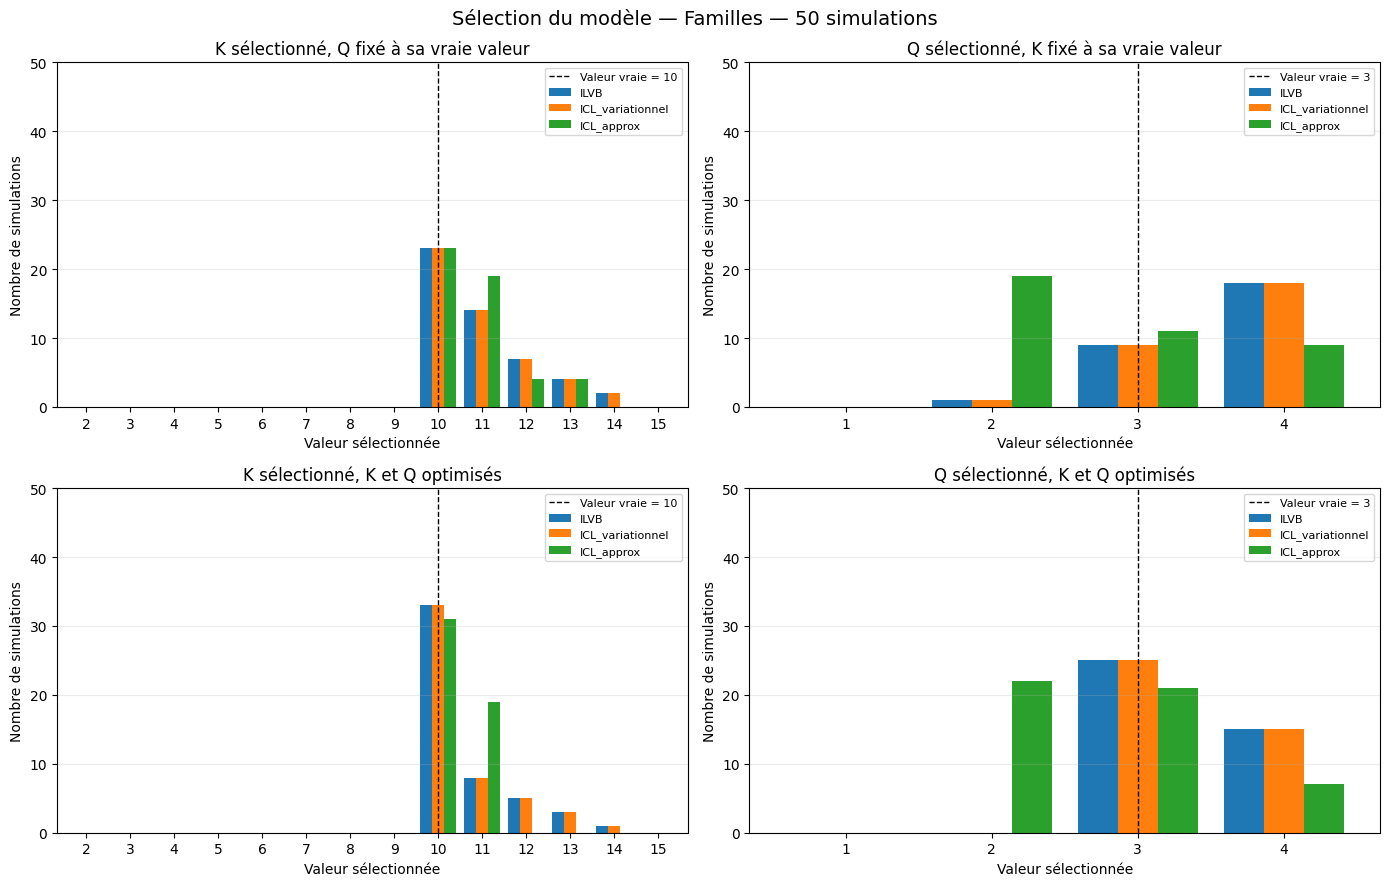

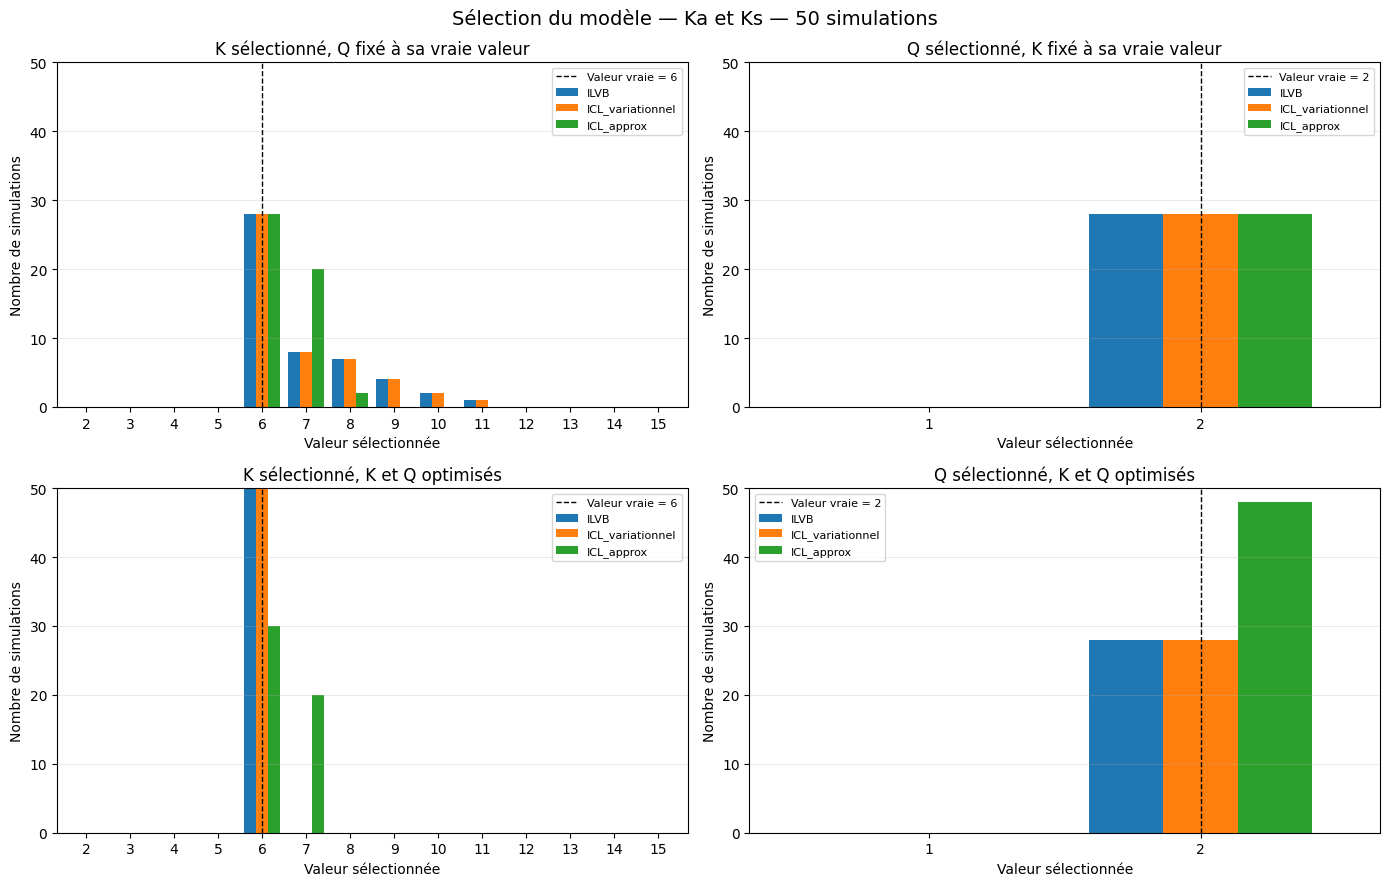

Résultats enregistrés dans : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/mimiSBM/Plots/mimiSBM/simulation_model_selection


In [ ]:
# Sauvegarde des sélections individuelles.
output_dir = repo_root / "Plots" / "mimiSBM" / "simulation_model_selection"
output_dir.mkdir(parents=True, exist_ok=True)
# resultats_selection.to_csv(
#     output_dir / "selections_50_simulations.csv",
#     index=False,
# )
resultats_selection = pd.read_csv(output_dir / "simulation_selection_K_Q.csv")

# Quatre bar plots par jeu : fréquences de K ou Q sélectionnés.
for nom_jeu, (_, K_vrai, Q_vrai) in jeux.items():
    donnees_jeu = resultats_selection[resultats_selection["jeu"] == nom_jeu]

    panneaux = [
        ("K avec Q vrai", "K_selectionne", list(K_CANDIDATS), K_vrai,
         "K sélectionné, Q fixé à sa vraie valeur"),
        ("Q avec K vrai", "Q_selectionne", list(range(1, A_kaks.shape[2] + 1))
         if nom_jeu == "Ka et Ks" else list(range(1, A_familles.shape[2] + 1)),
         Q_vrai, "Q sélectionné, K fixé à sa vraie valeur"),
        ("Sélection conjointe", "K_selectionne", list(K_CANDIDATS), K_vrai,
         "K sélectionné, K et Q optimisés"),
        ("Sélection conjointe", "Q_selectionne",
         list(range(1, A_kaks.shape[2] + 1))
         if nom_jeu == "Ka et Ks" else list(range(1, A_familles.shape[2] + 1)),
         Q_vrai, "Q sélectionné, K et Q optimisés"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.ravel()

    for ax, (strategie, colonne, valeurs, vrai, titre) in zip(axes, panneaux):
        subset = donnees_jeu[donnees_jeu["strategie"] == strategie]

        frequences = (
            subset.groupby([colonne, "critere"])
            .size()
            .unstack(fill_value=0)
            .reindex(index=valeurs, fill_value=0)
            .reindex(columns=CRITERES, fill_value=0)
        )

        frequences.plot(kind="bar", ax=ax, width=0.82)
        ax.axvline(
            valeurs.index(vrai),
            color="black",
            linestyle="--",
            linewidth=1,
            label=f"Valeur vraie = {vrai}",
        )
        ax.set_title(titre)
        ax.set_xlabel("Valeur sélectionnée")
        ax.set_ylabel("Nombre de simulations")
        ax.set_xticklabels([str(v) for v in valeurs], rotation=0)
        ax.set_ylim(0, N_SIMULATIONS)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(fontsize=8)

    fig.suptitle(
        f"Sélection du modèle — {nom_jeu} — {N_SIMULATIONS} simulations",
        fontsize=14,
    )
    fig.tight_layout()
    fig.savefig(output_dir / f"frequences_{nom_jeu.replace(' ', '_')}.png", dpi=150)
    plt.show()

print(f"Résultats enregistrés dans : {output_dir}")

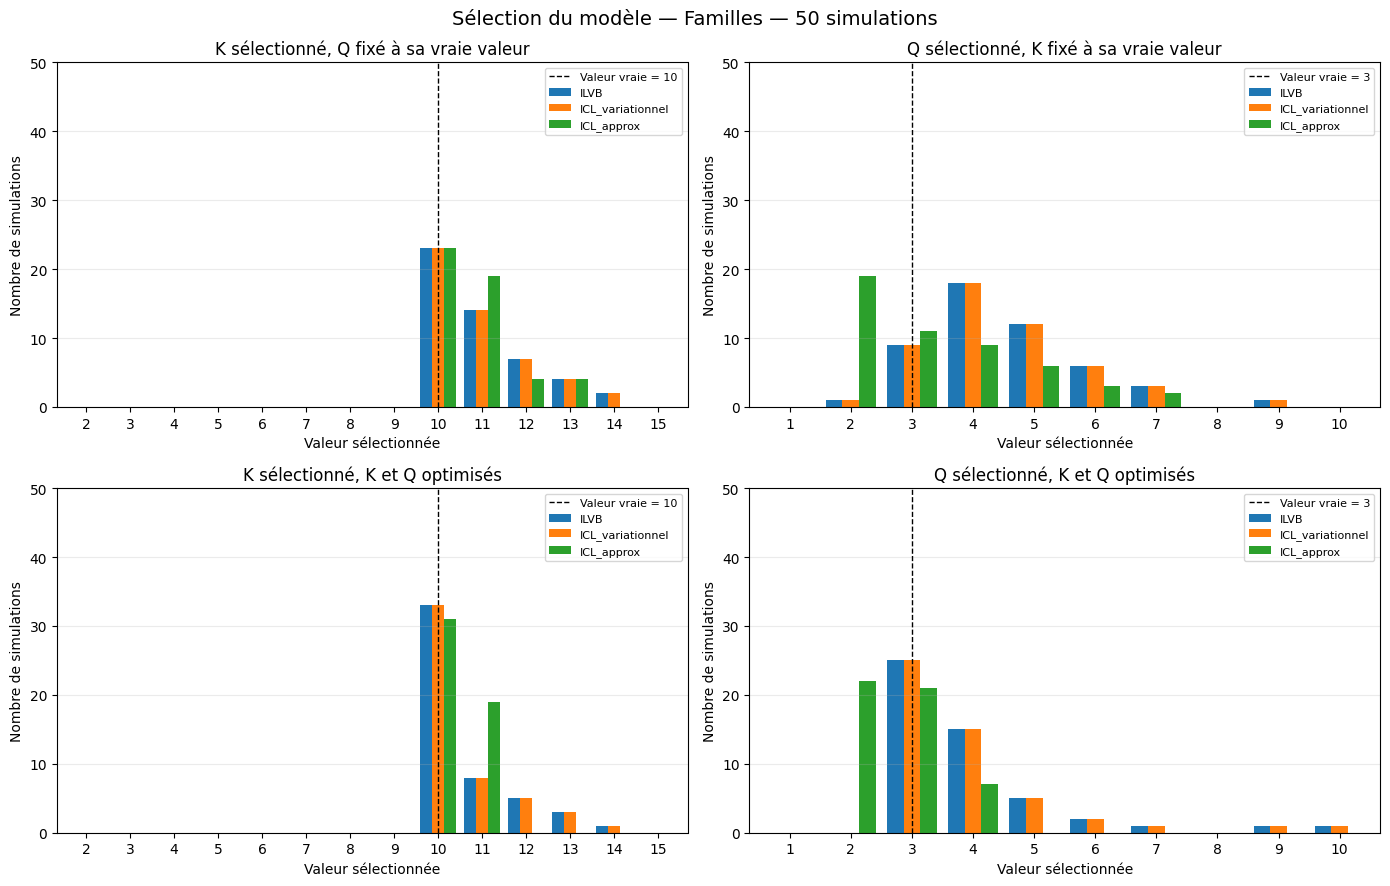

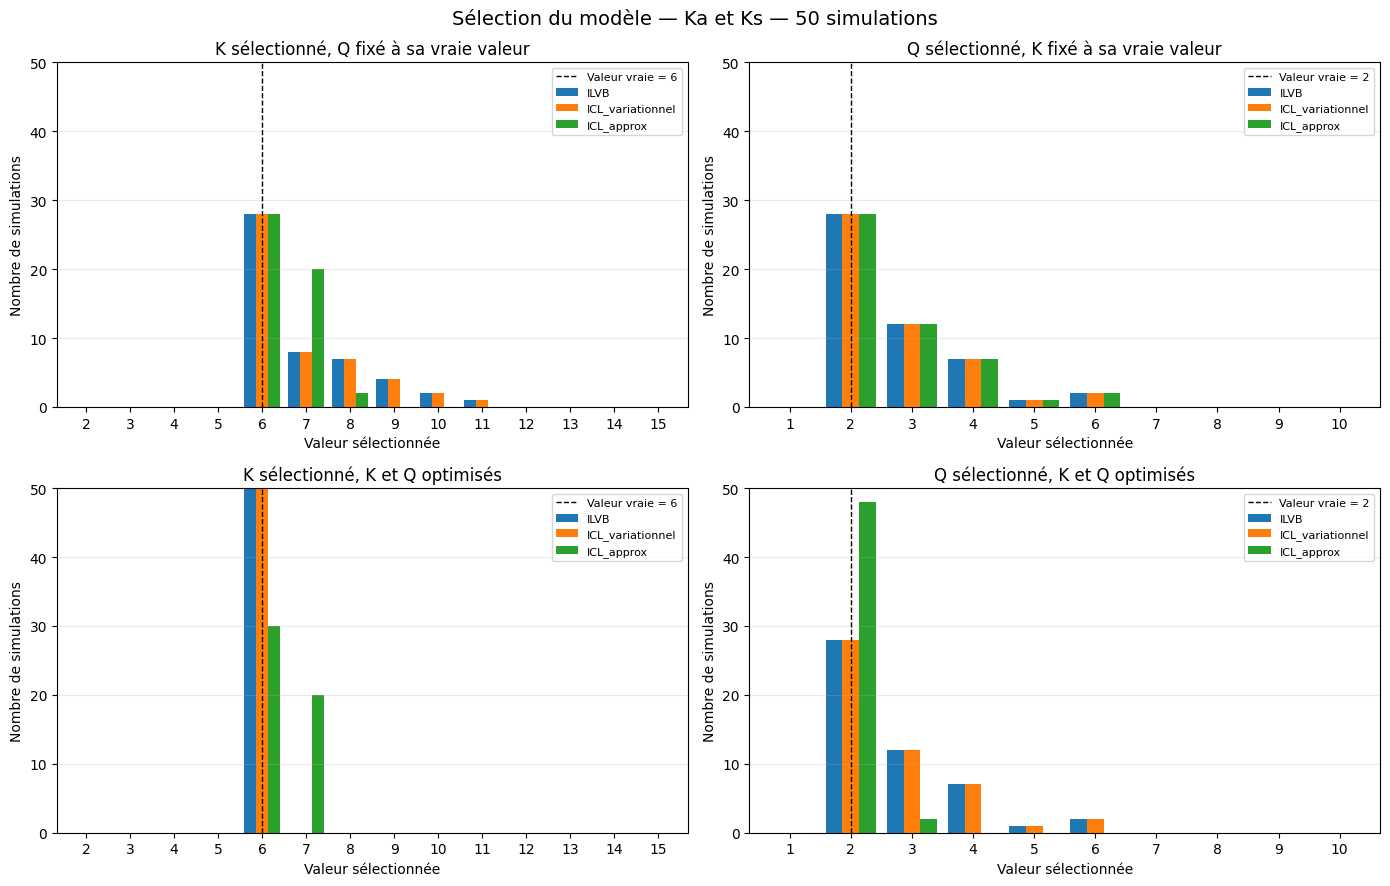

Résultats enregistrés dans : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/mimiSBM/Plots/mimiSBM/simulation_model_selection_v2


In [32]:
# Sauvegarde des sélections individuelles.
output_dir = repo_root / "Plots" / "mimiSBM" / "simulation_model_selection_v2"
output_dir.mkdir(parents=True, exist_ok=True)
# resultats_selection.to_csv(
#     output_dir / "selections_50_simulations.csv",
#     index=False,
# )


# Quatre bar plots par jeu : fréquences de K ou Q sélectionnés.
for nom_jeu, (_, K_vrai, Q_vrai) in jeux.items():
    donnees_jeu = resultats_selection[resultats_selection["jeu"] == nom_jeu]

    panneaux = [
        ("K avec Q vrai", "K_selectionne", list(K_CANDIDATS), K_vrai,
         "K sélectionné, Q fixé à sa vraie valeur"),
        ("Q avec K vrai", "Q_selectionne", list(range(1, 11)),
         Q_vrai, "Q sélectionné, K fixé à sa vraie valeur"),
        ("Sélection conjointe", "K_selectionne", list(K_CANDIDATS), K_vrai,
         "K sélectionné, K et Q optimisés"),
        ("Sélection conjointe", "Q_selectionne", list(range(1, 11)),
         Q_vrai, "Q sélectionné, K et Q optimisés"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.ravel()

    for ax, (strategie, colonne, valeurs, vrai, titre) in zip(axes, panneaux):
        subset = donnees_jeu[donnees_jeu["strategie"] == strategie]

        frequences = (
            subset.groupby([colonne, "critere"])
            .size()
            .unstack(fill_value=0)
            .reindex(index=valeurs, fill_value=0)
            .reindex(columns=CRITERES, fill_value=0)
        )

        frequences.plot(kind="bar", ax=ax, width=0.82)
        ax.axvline(
            valeurs.index(vrai),
            color="black",
            linestyle="--",
            linewidth=1,
            label=f"Valeur vraie = {vrai}",
        )
        ax.set_title(titre)
        ax.set_xlabel("Valeur sélectionnée")
        ax.set_ylabel("Nombre de simulations")
        ax.set_xticklabels([str(v) for v in valeurs], rotation=0)
        ax.set_ylim(0, N_SIMULATIONS)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(fontsize=8)

    fig.suptitle(
        f"Sélection du modèle — {nom_jeu} — {N_SIMULATIONS} simulations",
        fontsize=14,
    )
    fig.tight_layout()
    fig.savefig(output_dir / f"frequences_{nom_jeu.replace(' ', '_')}.png", dpi=150)
    plt.show()

print(f"Résultats enregistrés dans : {output_dir}")

### Tests v2 comme dans papier

In [35]:
import os
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

# ---------- Données : tenseurs existants, vues dupliquées jusqu'à V = 10 ----------
A_familles, vues_familles = charger_tenseur(paths_familles)
A_kaks, vues_kaks = charger_tenseur(paths_kaks)

N_SIMULATIONS = 50          # nombre de réplicats
K_CANDIDATS = range(2, 16)
Q_CANDIDATS = range(1, 11)
V_CIBLE = max(Q_CANDIDATS)  # il faut V >= Q max
TAUX_BRUIT = 0.0            # 0 = tenseurs tels quels ; ex. 0.02 = 2 % d'arêtes retournées
N_INIT_SIM = 3
MAX_ITER_SIM = 100
TOL_SIM = 1e-6
PRIORS_SIM = "jeffreys"
CRITERES = ("ILVB", "ICL_variationnel", "ICL_approx")


def dupliquer_vues(A, v_cible):
    """Répète cycliquement les vues. Une copie appartient à la même composante que l'originale."""
    indices = np.arange(v_cible) % A.shape[2]
    return A[:, :, indices], indices


jeux = {}
for nom, (A, K_vrai, Q_vrai, vues) in {
    "Familles": (A_familles, 10, 3, vues_familles),
    "Ka et Ks": (A_kaks, 6, 2, vues_kaks),
}.items():
    A_dup, indices = dupliquer_vues(A, V_CIBLE)
    jeux[nom] = (A_dup, K_vrai, Q_vrai)
    print(f"{nom} : {A.shape} -> {A_dup.shape}, vues = {[vues[i] for i in indices]}")


def bruiter(A, taux, rng):
    """Retourne chaque arête avec probabilité `taux`, indépendamment dans chaque vue (symétrique)."""
    if taux == 0:
        return A
    A = A.copy()
    N, _, V = A.shape
    for v in range(V):
        flips = np.triu(rng.random((N, N)) < taux, k=1)
        flips = flips | flips.T
        A[:, :, v] = np.where(flips, 1 - A[:, :, v], A[:, :, v])
    return A


# ---------- Scores et ajustement ----------
def calculer_scores(model, N, V):
    ilvb = model.elbo_
    icl_variationnel = ilvb - (
        entr(model.cluster_responsibilities_).sum()
        + entr(model.component_responsibilities_).sum()
    )
    K, Q = model.n_clusters, model.n_components
    penalite = (
        0.5 * (K * (K + 1) / 2 * Q) * np.log(V * N * (N - 1) / 2)
        + 0.5 * (K - 1) * np.log(N)
        + 0.5 * (Q - 1) * np.log(V)
    )
    return {"ILVB": ilvb, "ICL_variationnel": icl_variationnel, "ICL_approx": ilvb - penalite}


def ajuster_modele(A, K, Q, seed):
    """Meilleur ELBO sur N_INIT_SIM initialisations ; None si toutes échouent (NaN)."""
    meilleur_modele, meilleur_elbo = None, -np.inf
    for init in range(N_INIT_SIM):
        modele = MimiSBM(
            n_clusters=K, n_components=Q,
            clusters_prior=PRIORS_SIM, components_prior=PRIORS_SIM, adjacency_prior=PRIORS_SIM,
            max_iter=MAX_ITER_SIM, tol=TOL_SIM, random_state=seed + init,
        )
        try:
            modele.fit(A)
        except ValueError as exc:
            if "Probabilities contain NaN" in str(exc):
                continue
            raise
        elbo = float(modele.elbo_)
        if np.isfinite(elbo) and elbo > meilleur_elbo:
            meilleur_modele, meilleur_elbo = modele, elbo
    return meilleur_modele


# ---------- Un réplicat = toute la grille (K, Q), un seul ajustement par couple ----------
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

OUTPUT_DIR = Path(f"selection_modele_bruit{TAUX_BRUIT}")
(OUTPUT_DIR / "grilles").mkdir(parents=True, exist_ok=True)
N_JOBS = max(1, (os.cpu_count() or 2) - 1)


def executer_replicat(nom_jeu, indice_jeu, A, K_vrai, Q_vrai, replicat):
    chemin = OUTPUT_DIR / "grilles" / f"{nom_jeu.replace(' ', '_')}_rep{replicat + 1:02d}.csv"
    if chemin.exists():                       # reprise après interruption
        return str(chemin)

    N, _, V = A.shape
    seed_rep = 50_000 + indice_jeu * 10_000_000 + replicat

    with threadpool_limits(limits=1):         # 1 thread BLAS par worker
        A_rep = bruiter(A, TAUX_BRUIT, np.random.default_rng(seed_rep))
        lignes = []
        for K in K_CANDIDATS:
            for Q in Q_CANDIDATS:
                seed_fit = int(
                    np.random.SeedSequence([seed_rep, K, Q]).generate_state(1)[0] % (2**31 - 1000)
                )
                modele = ajuster_modele(A_rep, K, Q, seed_fit)
                scores = dict.fromkeys(CRITERES, np.nan) if modele is None \
                    else calculer_scores(modele, N, V)
                lignes.append({
                    "jeu": nom_jeu, "simulation": replicat + 1, "K": K, "Q": Q,
                    "K_vrai": K_vrai, "Q_vrai": Q_vrai, **scores,
                    "converged": bool(getattr(modele, "converged_", False)) if modele else False,
                })

    pd.DataFrame(lignes).to_csv(chemin, index=False)
    return str(chemin)


assert all(A.shape[2] >= max(Q_CANDIDATS) for A, _, _ in jeux.values())

taches = [
    (nom, i, A, K_vrai, Q_vrai, r)
    for i, (nom, (A, K_vrai, Q_vrai)) in enumerate(jeux.items())
    for r in range(N_SIMULATIONS)
]
Parallel(n_jobs=N_JOBS, verbose=5)(delayed(executer_replicat)(*t) for t in taches)

Familles : (444, 444, 4) -> (444, 444, 10), vues = ['Ka', 'Ks', 'Distance', 'Ka_Ks', 'Ka', 'Ks', 'Distance', 'Ka_Ks', 'Ka', 'Ks']
Ka et Ks : (444, 444, 2) -> (444, 444, 10), vues = ['Ka', 'Ks', 'Ka', 'Ks', 'Ka', 'Ks', 'Ka', 'Ks', 'Ka', 'Ks']


[Parallel(n_jobs=7)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=7)]: Done   4 tasks      | elapsed:  4.5min
[Parallel(n_jobs=7)]: Done  58 tasks      | elapsed: 33.1min
[Parallel(n_jobs=7)]: Done 100 out of 100 | elapsed: 54.2min finished


['selection_modele_bruit0.0/grilles/Familles_rep01.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep02.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep03.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep04.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep05.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep06.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep07.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep08.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep09.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep10.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep11.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep12.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep13.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep14.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep15.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep16.csv',
 'selection_modele_bruit0.0/grilles/Familles_rep17.csv',
 'selection_modele_bruit0.0/gri

K_ok   Q_ok  couple_ok
jeu      strategie           critere                                  
Familles K avec Q vrai       ICL_approx          0.0  100.0        0.0
                             ICL_variationnel    0.0  100.0        0.0
                             ILVB                0.0  100.0        0.0
         Q avec K vrai       ICL_approx        100.0    0.0        0.0
                             ICL_variationnel  100.0    0.0        0.0
                             ILVB              100.0    0.0        0.0
         Sélection conjointe ICL_approx          0.0    0.0        0.0
                             ICL_variationnel    0.0    0.0        0.0
                             ILVB                0.0    0.0        0.0
Ka et Ks K avec Q vrai       ICL_approx         90.0  100.0       90.0
                             ICL_variationnel   90.0  100.0       90.0
                             ILVB               90.0  100.0       90.0
         Q avec K vrai       ICL_approx        100.0   90.0       90.0
                             ICL_variationnel  100.0   90.0       90.0
                             ILVB              100.0   90.0       90.0
         Sélection conjointe ICL_approx         90.0  100.0       90.0
                             ICL_variationnel  100.0   90.0       90.0
                             ILVB              100.0   90.0       90.0

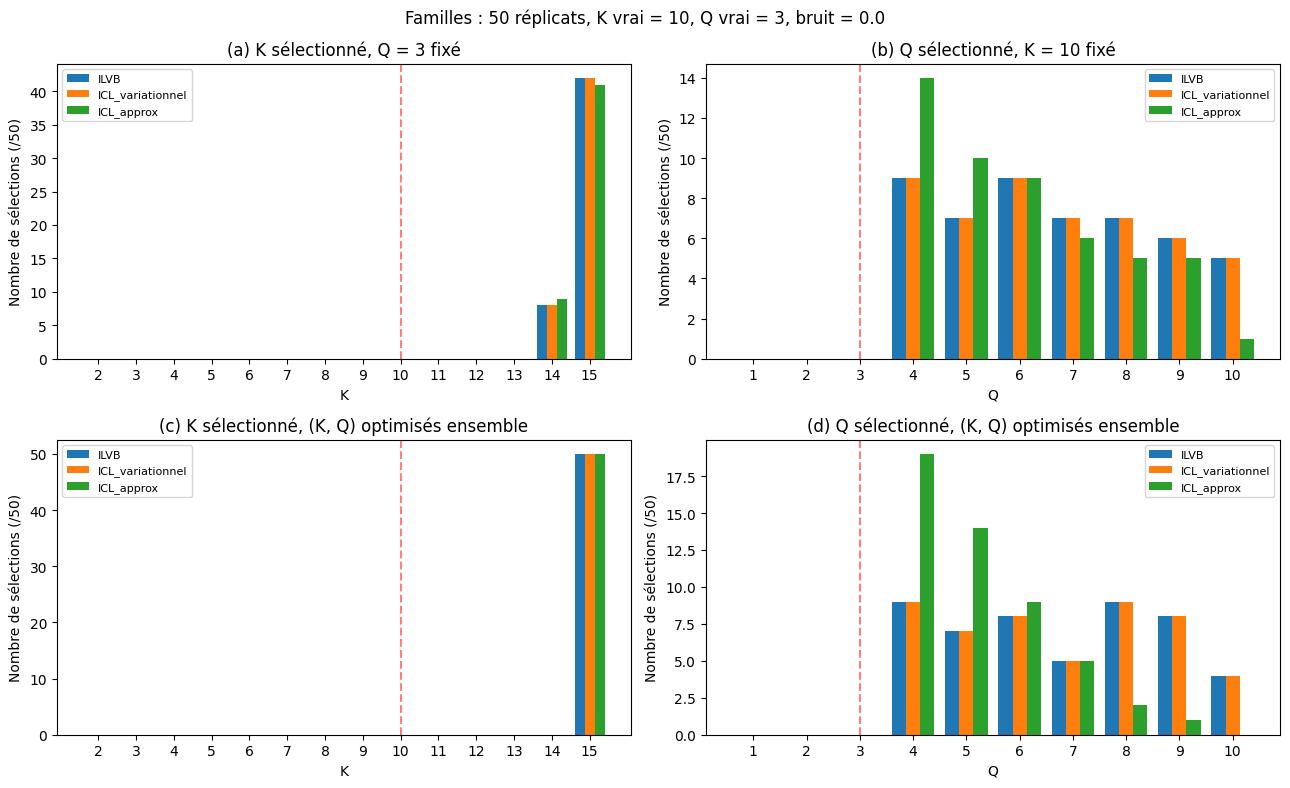

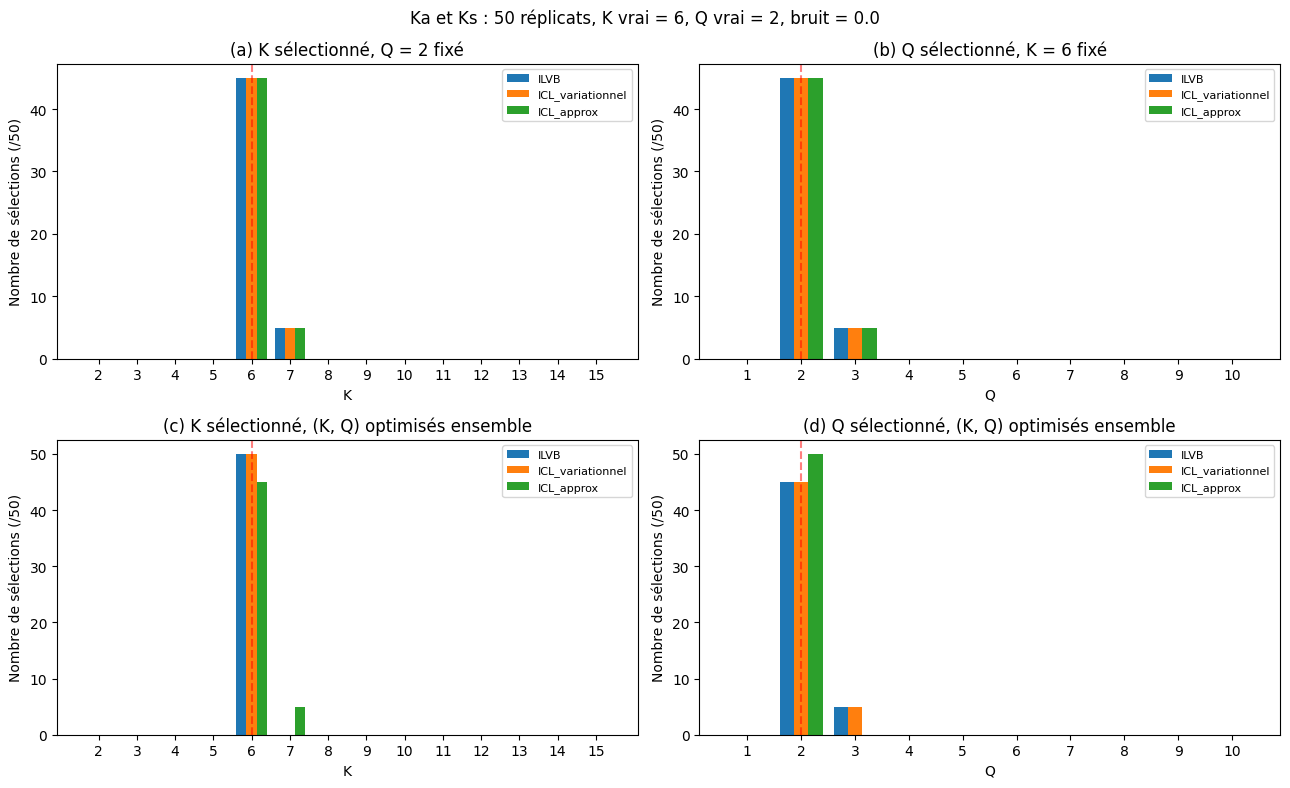

In [36]:
grilles = pd.concat(
    [pd.read_csv(p) for p in sorted((OUTPUT_DIR / "grilles").glob("*.csv"))], ignore_index=True
)
grilles.to_csv(OUTPUT_DIR / "grilles_completes.csv", index=False)


def selectionner(grilles):
    lignes = []
    for (jeu, sim), g in grilles.groupby(["jeu", "simulation"]):
        K_vrai, Q_vrai = int(g["K_vrai"].iloc[0]), int(g["Q_vrai"].iloc[0])
        strategies = {
            "K avec Q vrai": g[g["Q"] == Q_vrai],      # (a)
            "Q avec K vrai": g[g["K"] == K_vrai],      # (b)
            "Sélection conjointe": g,                  # (c) et (d)
        }
        for strat, cand in strategies.items():
            for crit in CRITERES:
                c = cand.dropna(subset=[crit])
                if c.empty:
                    continue
                best = c.loc[c[crit].idxmax()]
                lignes.append({
                    "jeu": jeu, "simulation": sim, "strategie": strat, "critere": crit,
                    "K_selectionne": int(best["K"]), "Q_selectionne": int(best["Q"]),
                    "K_vrai": K_vrai, "Q_vrai": Q_vrai,
                })
    return pd.DataFrame(lignes)


sel = selectionner(grilles)
sel["K_ok"] = sel["K_selectionne"] == sel["K_vrai"]
sel["Q_ok"] = sel["Q_selectionne"] == sel["Q_vrai"]
sel["couple_ok"] = sel["K_ok"] & sel["Q_ok"]
sel.to_csv(OUTPUT_DIR / "simulation_selection_K_Q.csv", index=False)

display(sel.groupby(["jeu", "strategie", "critere"])[["K_ok", "Q_ok", "couple_ok"]]
          .mean().mul(100).round(1))


def barres(ax, s, col, valeurs, vrai, titre, xlabel):
    valeurs = list(valeurs)
    largeur = 0.8 / len(CRITERES)
    x = np.arange(len(valeurs))
    for i, crit in enumerate(CRITERES):
        counts = s[s["critere"] == crit][col].value_counts().reindex(valeurs, fill_value=0)
        ax.bar(x + i * largeur, counts.values, largeur, label=crit)
    ax.set_xticks(x + largeur)
    ax.set_xticklabels(valeurs)
    ax.axvline(valeurs.index(vrai) + largeur, color="red", ls="--", alpha=0.5)
    ax.set(title=titre, xlabel=xlabel, ylabel=f"Nombre de sélections (/{N_SIMULATIONS})")
    ax.legend(fontsize=8)


for nom, (A, K_vrai, Q_vrai) in jeux.items():
    s = sel[sel["jeu"] == nom]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    barres(axes[0, 0], s[s.strategie == "K avec Q vrai"], "K_selectionne",
           K_CANDIDATS, K_vrai, f"(a) K sélectionné, Q = {Q_vrai} fixé", "K")
    barres(axes[0, 1], s[s.strategie == "Q avec K vrai"], "Q_selectionne",
           Q_CANDIDATS, Q_vrai, f"(b) Q sélectionné, K = {K_vrai} fixé", "Q")
    barres(axes[1, 0], s[s.strategie == "Sélection conjointe"], "K_selectionne",
           K_CANDIDATS, K_vrai, "(c) K sélectionné, (K, Q) optimisés ensemble", "K")
    barres(axes[1, 1], s[s.strategie == "Sélection conjointe"], "Q_selectionne",
           Q_CANDIDATS, Q_vrai, "(d) Q sélectionné, (K, Q) optimisés ensemble", "Q")
    fig.suptitle(f"{nom} : {N_SIMULATIONS} réplicats, K vrai = {K_vrai}, Q vrai = {Q_vrai}, bruit = {TAUX_BRUIT}")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"figure_selection_{nom.replace(' ', '_')}.png", dpi=200)
    plt.show()